<h1 align="center">PSL Week – Topological Data Analysis</h1>
<h2 align="center">Data project: identifying walkers from accelerometer data</h2>

**Goal.** Classify 200-point windows of 3-axis accelerometer data into persons A / B / C with a TDA pipeline
(filtration → persistence diagrams → vectorization → classifier), then predict the 22 unlabeled windows.

**Plan of the notebook**
1. Data exploration (and two important observations about the data)
2. Four filtrations, and what their diagrams look like
3. Diagram distances (bottleneck) + MDS: which filtration separates the classes?
4. Vectorizations (statistics, landscapes, silhouettes, persistence images)
5. Classification: systematic comparison under an honest (blocked, purged) cross-validation
6. Final model, interpretation, and prediction of the evaluation set

In [1]:
import numpy as np, pickle, os, time, warnings
import pandas as pd
import matplotlib.pyplot as plt
import gudhi as gd
import gudhi.representations as gdr
from gudhi.point_cloud.timedelay import TimeDelayEmbedding
from sklearn import manifold
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import make_pipeline, make_union
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")
import tda_utils          # small helper module (parallel computations, see tda_utils.py)
plt.rcParams["figure.dpi"] = 100
COL = {"A": "tab:red", "B": "tab:green", "C": "tab:blue"}

with open("psl_week_acc_train_data.pkl", "rb") as f:
    X, y_raw = pickle.load(f)
y = np.array([l.decode() for l in y_raw])
with open("psl_week_acc_eval_data.pkl", "rb") as f:
    E = pickle.load(f)
print("train:", X.shape, " eval:", E.shape, " classes:", {c: int((y == c).sum()) for c in "ABC"})

train: (240, 200, 3)  eval: (22, 200, 3)  classes: {'A': 80, 'B': 80, 'C': 80}


# 1. Data exploration

Each sample is a window of $p=200$ consecutive accelerometer measurements $a(t)\in\mathbb{R}^3$.
We look at it in two ways: as a **time series** and as a **point cloud** in $\mathbb{R}^3$.

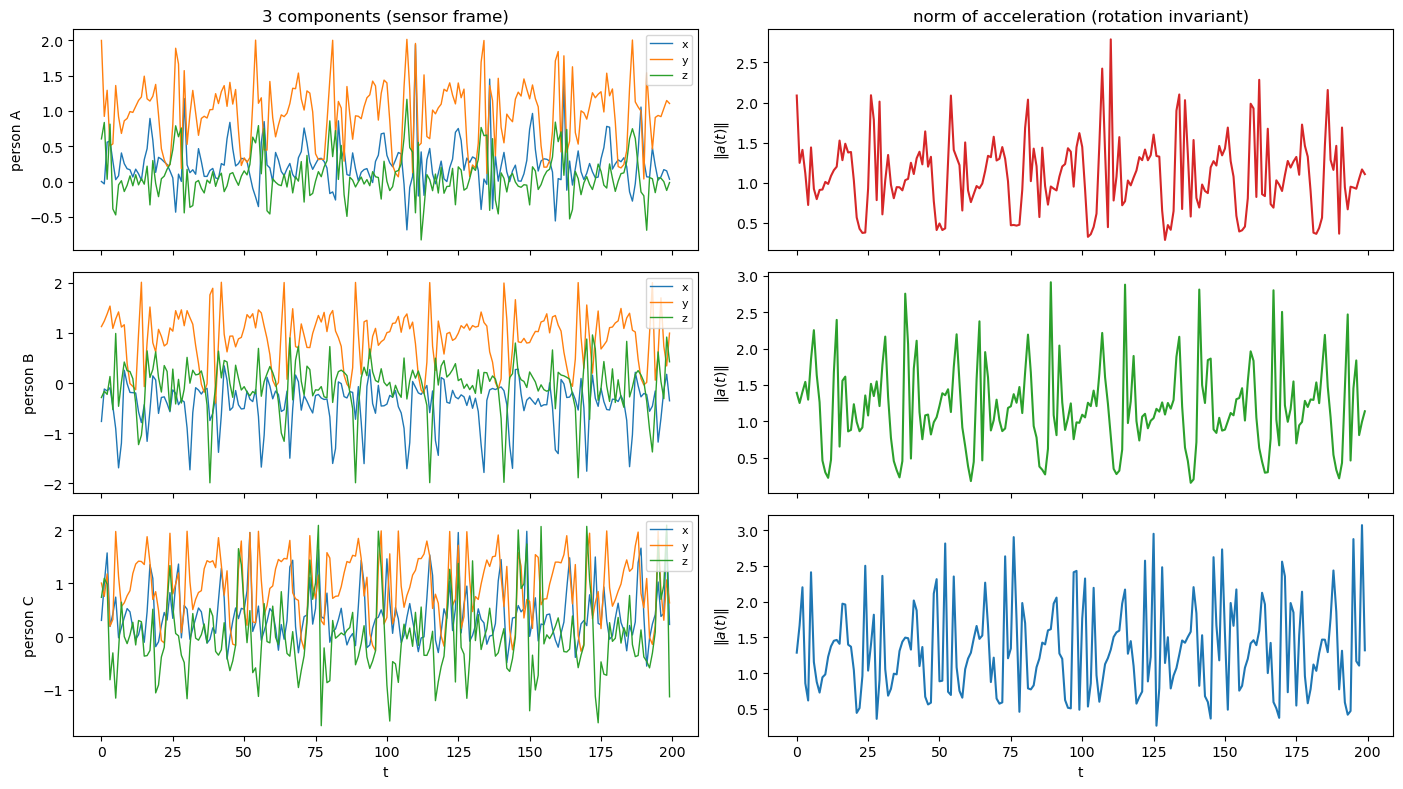

In [2]:
fig, axes = plt.subplots(3, 2, figsize=(14, 8), sharex=True)
for r, c in enumerate("ABC"):
    w = X[np.where(y == c)[0][0]]
    for k, lab in enumerate("xyz"):
        axes[r, 0].plot(w[:, k], label=lab, lw=1)
    axes[r, 0].set_ylabel(f"person {c}"); axes[r, 0].legend(loc="upper right", fontsize=8)
    axes[r, 1].plot(np.linalg.norm(w, axis=1), color=COL[c])
    axes[r, 1].set_ylabel(r"$\|a(t)\|$")
axes[0, 0].set_title("3 components (sensor frame)"); axes[0, 1].set_title("norm of acceleration (rotation invariant)")
axes[2, 0].set_xlabel("t"); axes[2, 1].set_xlabel("t")
plt.tight_layout(); plt.show()

**Observation.** Walking is (quasi-)periodic: the norm $\|a(t)\|$ shows one peak per step (heel strike),
with period around 25–35 samples. The amplitude, sharpness and regularity of the peaks differ between persons.

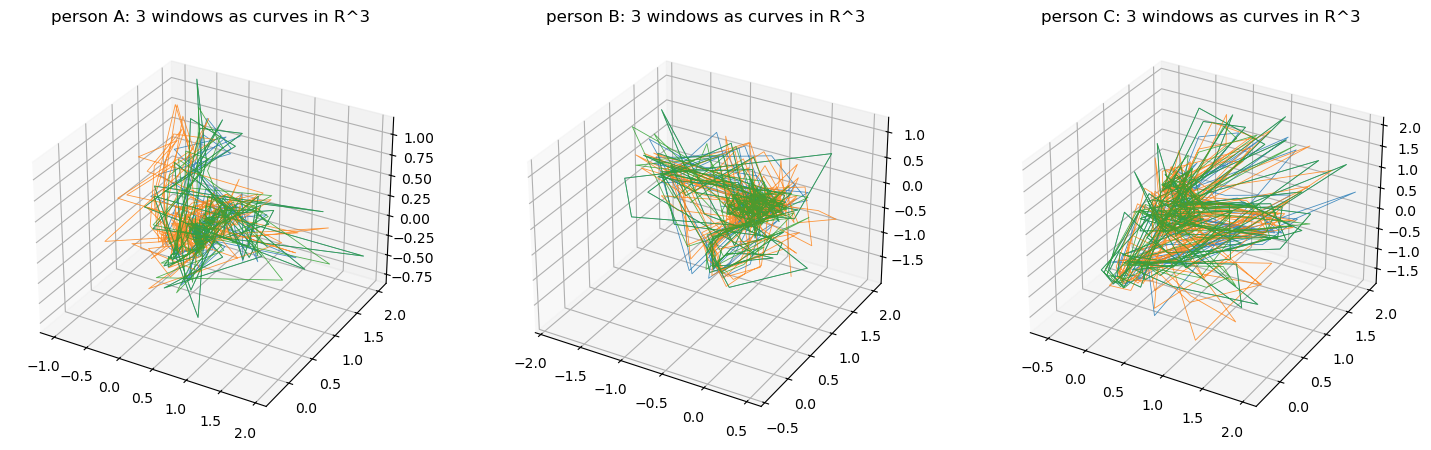

In [3]:
fig = plt.figure(figsize=(15, 4.5))
for k, c in enumerate("ABC"):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    for i in np.where(y == c)[0][:3]:
        ax.plot(*X[i].T, lw=0.6, alpha=0.8)
    ax.set_title(f"person {c}: 3 windows as curves in R^3")
plt.tight_layout(); plt.show()

### Observation 1 – orientation of the phone

The mean of each window is essentially the **gravity vector** expressed in the phone's frame.
Because each person carried the phone in a different orientation, this mean is almost constant per person:

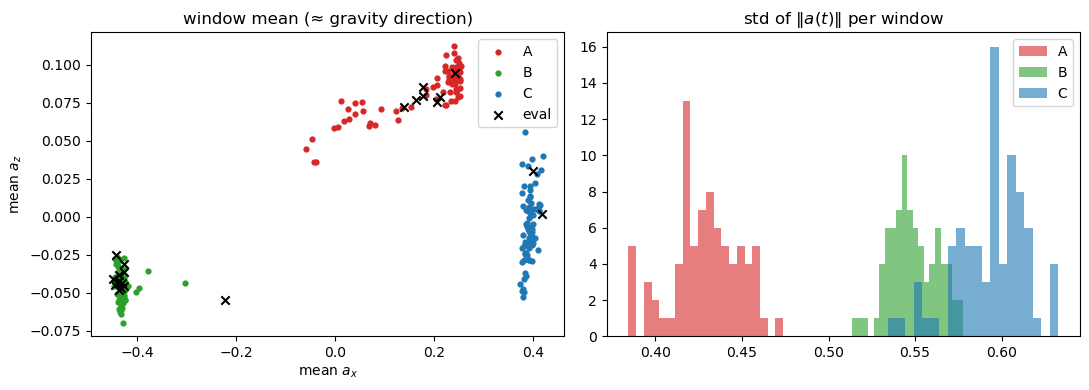

In [4]:
M = X.mean(axis=1)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for c in "ABC":
    ax[0].scatter(M[y == c, 0], M[y == c, 2], s=12, c=COL[c], label=c)
ax[0].scatter(E.mean(1)[:, 0], E.mean(1)[:, 2], marker="x", c="k", label="eval")
ax[0].set_xlabel("mean $a_x$"); ax[0].set_ylabel("mean $a_z$"); ax[0].legend(); ax[0].set_title("window mean (≈ gravity direction)")
for c in "ABC":
    ax[1].hist(np.linalg.norm(X[y == c], axis=2).std(1), bins=20, alpha=.6, color=COL[c], label=c)
ax[1].set_title(r"std of $\|a(t)\|$ per window"); ax[1].legend()
plt.tight_layout(); plt.show()

This is a *non-topological shortcut*: it identifies the **phone position**, not the **gait**. It would break as soon as
someone puts the phone in another pocket. We therefore build **rotation-invariant** topological features and only use the
orientation as an independent **sanity check** at the end.

Rotation invariance of our filtrations:
* Alpha / Rips complex on the cloud $\{a(t)\}\subset\mathbb{R}^3$: depend only on pairwise distances → invariant under rotations.
* Anything built from $\|a(t)\|$: invariant under rotations by construction.

### Observation 2 – the windows overlap

The windows were cut with a sliding window from one long recording per person. Many 3D samples appear in several windows.
Using these shared samples we can recover the **position (time offset)** of every window in its original recording.

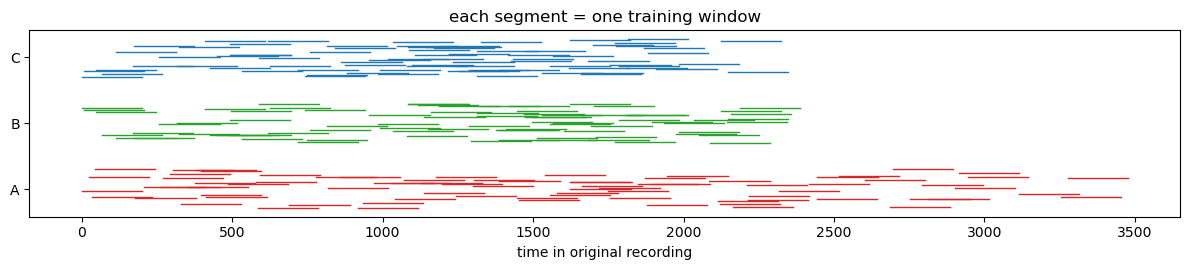

In [5]:
def window_offsets(W):
    # Recover the start time of each window from samples shared between overlapping windows.
    loc = {}
    for i in range(len(W)):
        for t in range(W.shape[1]):
            loc.setdefault(tuple(W[i, t]), []).append((i, t))
    pos, stack = {0: 0}, [0]
    while stack:
        i = stack.pop()
        for t in range(W.shape[1]):
            for j, u in loc[tuple(W[i, t])]:
                if j not in pos:
                    pos[j] = pos[i] + t - u; stack.append(j)
    o = np.array([pos[i] for i in range(len(W))]); return o - o.min()

offset = np.zeros(len(y), int)
for c in "ABC":
    idx = np.where(y == c)[0]; offset[idx] = window_offsets(X[idx])

fig, ax = plt.subplots(figsize=(12, 2.8))
for k, c in enumerate("ABC"):
    for o in offset[y == c]:
        ax.plot([o, o + 200], [k + np.random.uniform(-.3, .3)] * 2, color=COL[c], lw=1)
ax.set_yticks([0, 1, 2]); ax.set_yticklabels(list("ABC")); ax.set_xlabel("time in original recording")
ax.set_title("each segment = one training window"); plt.tight_layout(); plt.show()

**Consequence for model evaluation.** A plain random K-fold puts heavily overlapping windows in train and test, so the test
score is optimistic. We will use a **blocked & purged cross-validation**: each recording is split into 5 contiguous time blocks;
one block is the test fold and every training window that overlaps the test block in time is removed.

In [6]:
fold = np.zeros(len(y), int)
for c in "ABC":
    m = y == c; fold[m] = np.minimum(offset[m] * 5 // (offset[m].max() + 1), 4)

def blocked_purged_splits():
    for g in range(5):
        te = fold == g; tr = ~te
        for c in "ABC":
            m = y == c; lo, hi = offset[te & m].min(), offset[te & m].max() + 200
            tr &= ~(m & (offset + 200 > lo) & (offset < hi))
        yield np.where(tr)[0], np.where(te)[0]

for k, (tr, te) in enumerate(blocked_purged_splits()):
    print(f"fold {k}: train {len(tr):3d}  test {len(te):3d}")
random_cv = StratifiedKFold(5, shuffle=True, random_state=0)

fold 0: train 177  test  45
fold 1: train 169  test  44
fold 2: train 148  test  57
fold 3: train 148  test  55
fold 4: train 185  test  39


# 2. Filtrations and persistence diagrams

We compare four constructions. Notation: $a(t)\in\mathbb{R}^3$, $s(t)=\|a(t)\|$.

| | complex / filtration | input | what it captures |
|---|---|---|---|
| **F1** | Alpha complex (radius filtration) | cloud $\{a(t)\}\subset\mathbb{R}^3$ | shape of the 3D acceleration loop (one loop per gait cycle) |
| **F2** | Vietoris–Rips | delay embedding $(a(t),a(t+2),a(t+4))\in\mathbb{R}^9$ ($m=3$, $\tau=2$) | local dynamics (suggested in the subject) |
| **F3** | Alpha complex | Takens embedding of $s$: $(s(t),s(t+\tau),s(t+2\tau))\in\mathbb{R}^3$, $\tau=5$ | periodicity of the step signal → $H_1$ loop |
| **F4** | lower-star (sublevel) filtration on the path graph | $s$ and $-s$ | peaks & valleys of $s$ (step impacts), $H_0$ |

*Reminders.*
- **Alpha complex**: subcomplex of the Delaunay triangulation; a simplex enters at the radius where the balls around its vertices
  (restricted to their Voronoi cells) have a common point. It is homotopy-equivalent to the union of balls (nerve theorem), and much smaller than Čech/Rips.
  Gudhi gives the *squared* radius, so we take the square root.
- **Rips complex**: a simplex enters as soon as all pairwise distances are $\le r$. It is easy to compute in any dimension but gets large.
- **Time-delay (Takens) embedding**: a periodic signal becomes a closed curve, hence a long-lived $H_1$ class; its size relates to the amplitude of the oscillation.
- **Sublevel filtration of a function** on a graph: vertex $i$ enters at $s(i)$, edge $(i,i+1)$ at $\max(s(i),s(i+1))$.
  $H_0$ classes are born at local minima and die when they merge (elder rule). A point $(b,d)$ is a "valley" of depth $d-b$.
  Doing the same with $-s$ (superlevel filtration) describes the **peaks**. Stability: $d_B(\mathrm{Dgm}(f),\mathrm{Dgm}(g))\le\|f-g\|_\infty$.

In [7]:
def finite(d):
    d = np.asarray(d, float).reshape(-1, 2); return d[np.isfinite(d[:, 1])]

def F1_alpha_raw(w):
    st = gd.AlphaComplex(points=w).create_simplex_tree(); st.compute_persistence()
    return [np.sqrt(finite(st.persistence_intervals_in_dimension(k))) for k in (0, 1)]

def F2_rips_td(w, m=3, delay=2):
    # gudhi: `dim` is the TOTAL output dimension -> 3*m for a 3D series (dim=3 would mean: no embedding at all!)
    pc = TimeDelayEmbedding(dim=3 * m, delay=delay, skip=1)(w)       # (a(t), a(t+2), a(t+4)) in R^9
    st = gd.RipsComplex(points=pc).create_simplex_tree(max_dimension=2); st.compute_persistence()
    return [finite(st.persistence_intervals_in_dimension(k)) for k in (0, 1)]

def F3_norm_takens(w, dim=3, delay=5):
    pc = TimeDelayEmbedding(dim=dim, delay=delay, skip=1)(np.linalg.norm(w, axis=1))
    st = gd.AlphaComplex(points=pc).create_simplex_tree(); st.compute_persistence()
    return [np.sqrt(finite(st.persistence_intervals_in_dimension(k))) for k in (0, 1)]

def sublevel_H0(f):
    st = gd.SimplexTree()
    for i, v in enumerate(f): st.insert([i], v)
    for i in range(len(f) - 1): st.insert([i, i + 1], max(f[i], f[i + 1]))
    st.compute_persistence(); return finite(st.persistence_intervals_in_dimension(0))

def F4_norm_sublevel(w):
    s = np.linalg.norm(w, axis=1)
    return [sublevel_H0(s), sublevel_H0(-s)]    # [valleys, peaks]

FILTRATIONS = {"F1 alpha(R^3)": (F1_alpha_raw, ["H0", "H1"]),
               "F2 rips(TD R^9)": (F2_rips_td, ["H0", "H1"]),
               "F3 alpha(Takens |a|)": (F3_norm_takens, ["H0", "H1"]),
               "F4 sublevel |a|": (F4_norm_sublevel, ["H0 sub", "H0 super"])}

In [8]:
XE = np.concatenate([X, E])          # diagrams are unsupervised -> compute them once for train + eval
DIAGS = {}
for name, (f, dims) in FILTRATIONS.items():
    cache = "cache_" + name.split()[0] + ".pkl"
    t = time.time()
    if os.path.exists(cache):
        DIAGS[name] = pickle.load(open(cache, "rb"))
    else:
        if name.startswith("F2"): DIAGS[name] = tda_utils.parallel_rips_td(XE, 3, 2)   # same function, run on all cores
        else: DIAGS[name] = [f(w) for w in XE]
        pickle.dump(DIAGS[name], open(cache, "wb"))
    print(f"{name:22s} {time.time() - t:6.1f}s   mean #points per dim:",
          [round(np.mean([len(d[k]) for d in DIAGS[name]]), 1) for k in range(len(dims))])
train_diags = {k: v[:240] for k, v in DIAGS.items()}
eval_diags = {k: v[240:] for k, v in DIAGS.items()}

F1 alpha(R^3)             0.0s   mean #points per dim: [199.0, 330.6]
F2 rips(TD R^9)           0.0s   mean #points per dim: [195.0, 49.5]
F3 alpha(Takens |a|)      0.0s   mean #points per dim: [189.0, 304.1]
F4 sublevel |a|           0.0s   mean #points per dim: [52.6, 52.5]


Below: one representative diagram per person (columns) for every filtration (rows).

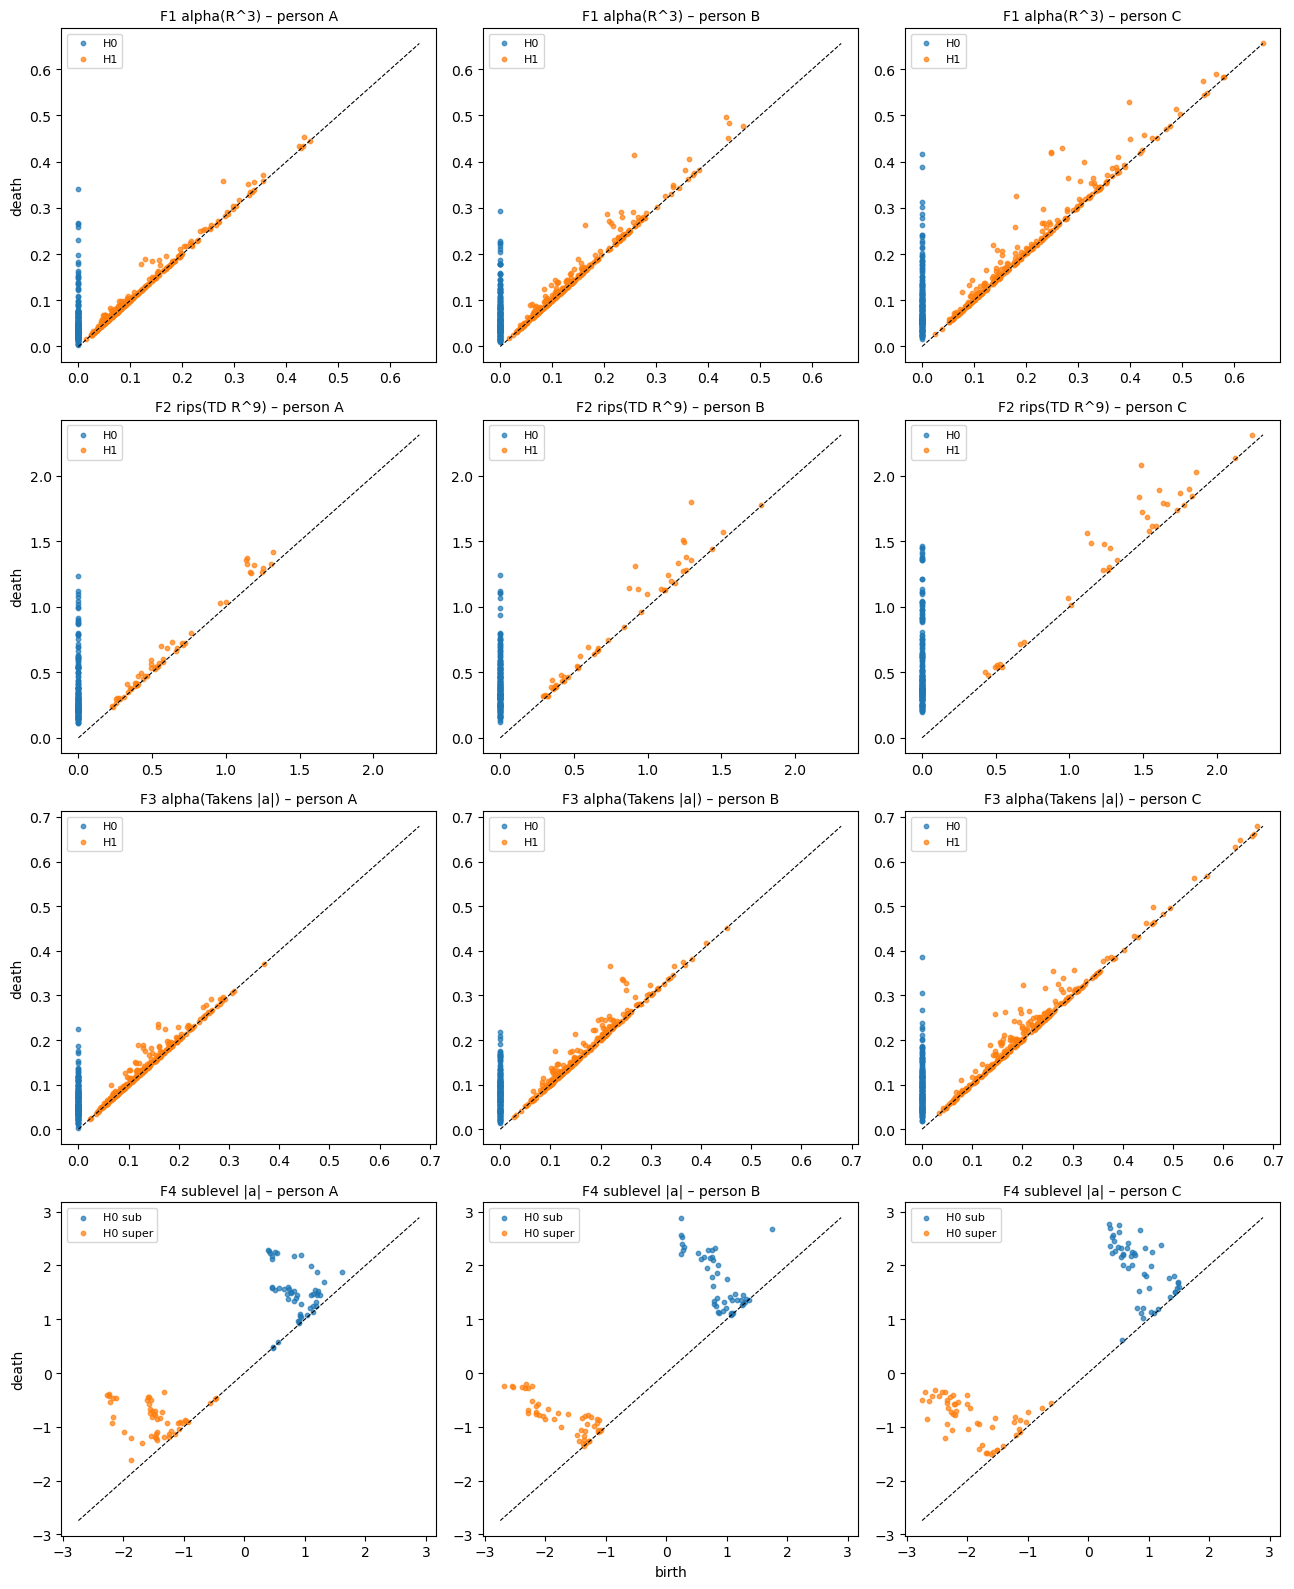

In [9]:
reps = {c: np.where(y == c)[0][5] for c in "ABC"}
fig, axes = plt.subplots(4, 3, figsize=(13, 16))
for r, (name, (_, dims)) in enumerate(FILTRATIONS.items()):
    allp = np.vstack([d for i in reps.values() for d in train_diags[name][i]])
    lo, hi = allp.min(), allp.max()
    for k, c in enumerate("ABC"):
        ax = axes[r, k]
        for j, (dg, lab) in enumerate(zip(train_diags[name][reps[c]], dims)):
            ax.scatter(dg[:, 0], dg[:, 1], s=10, alpha=.7, label=lab)
        ax.plot([lo, hi], [lo, hi], "k--", lw=.8)
        ax.set_title(f"{name} – person {c}", fontsize=10); ax.legend(fontsize=8)
        if k == 0: ax.set_ylabel("death")
axes[-1, 1].set_xlabel("birth")
plt.tight_layout(); plt.show()

**Reading the diagrams.**
* F1/F3, $H_1$: the point far from the diagonal is the **gait-cycle loop**; its size reflects the amplitude of the movement.
* F4: in the *superlevel* diagram (peaks of $s$, plotted with $-s$) each step impact gives a point far from the diagonal;
  their number (≈ steps per window → **cadence**), height and persistence (→ **impact strength**) characterise the walker.

# 3. Distances between diagrams and MDS

The **bottleneck distance** $d_B(D,D')=\inf_{\gamma}\sup_{x}\|x-\gamma(x)\|_\infty$ (optimal matching, points may be matched to the diagonal)
gives a metric on diagrams. If the 3 persons form separated groups in this metric space, the filtration is a good candidate.
We visualise the distance matrices and embed them in $\mathbb{R}^2$ with **metric MDS** (find points whose Euclidean distances best fit the matrix).

In [10]:
def bottleneck_matrix(diags):
    n = len(diags); B = np.zeros((n, n))
    for i in range(n):
        for j in range(i):
            B[i, j] = B[j, i] = gd.bottleneck_distance(diags[i], diags[j], 1e-3)
    return B

to_compare = [("F1 alpha(R^3)", 1), ("F2 rips(TD R^9)", 1), ("F3 alpha(Takens |a|)", 1), ("F4 sublevel |a|", 1), ("F4 sublevel |a|", 0)]
BMAT = {}
for name, k in to_compare:
    cache = f"cache_bottleneck_{name.split()[0]}_{k}.pkl"
    if os.path.exists(cache): BMAT[(name, k)] = pickle.load(open(cache, "rb"))
    else:
        t = time.time(); BMAT[(name, k)] = bottleneck_matrix([d[k] for d in train_diags[name]])
        pickle.dump(BMAT[(name, k)], open(cache, "wb")); print(name, k, f"{time.time() - t:.0f}s")

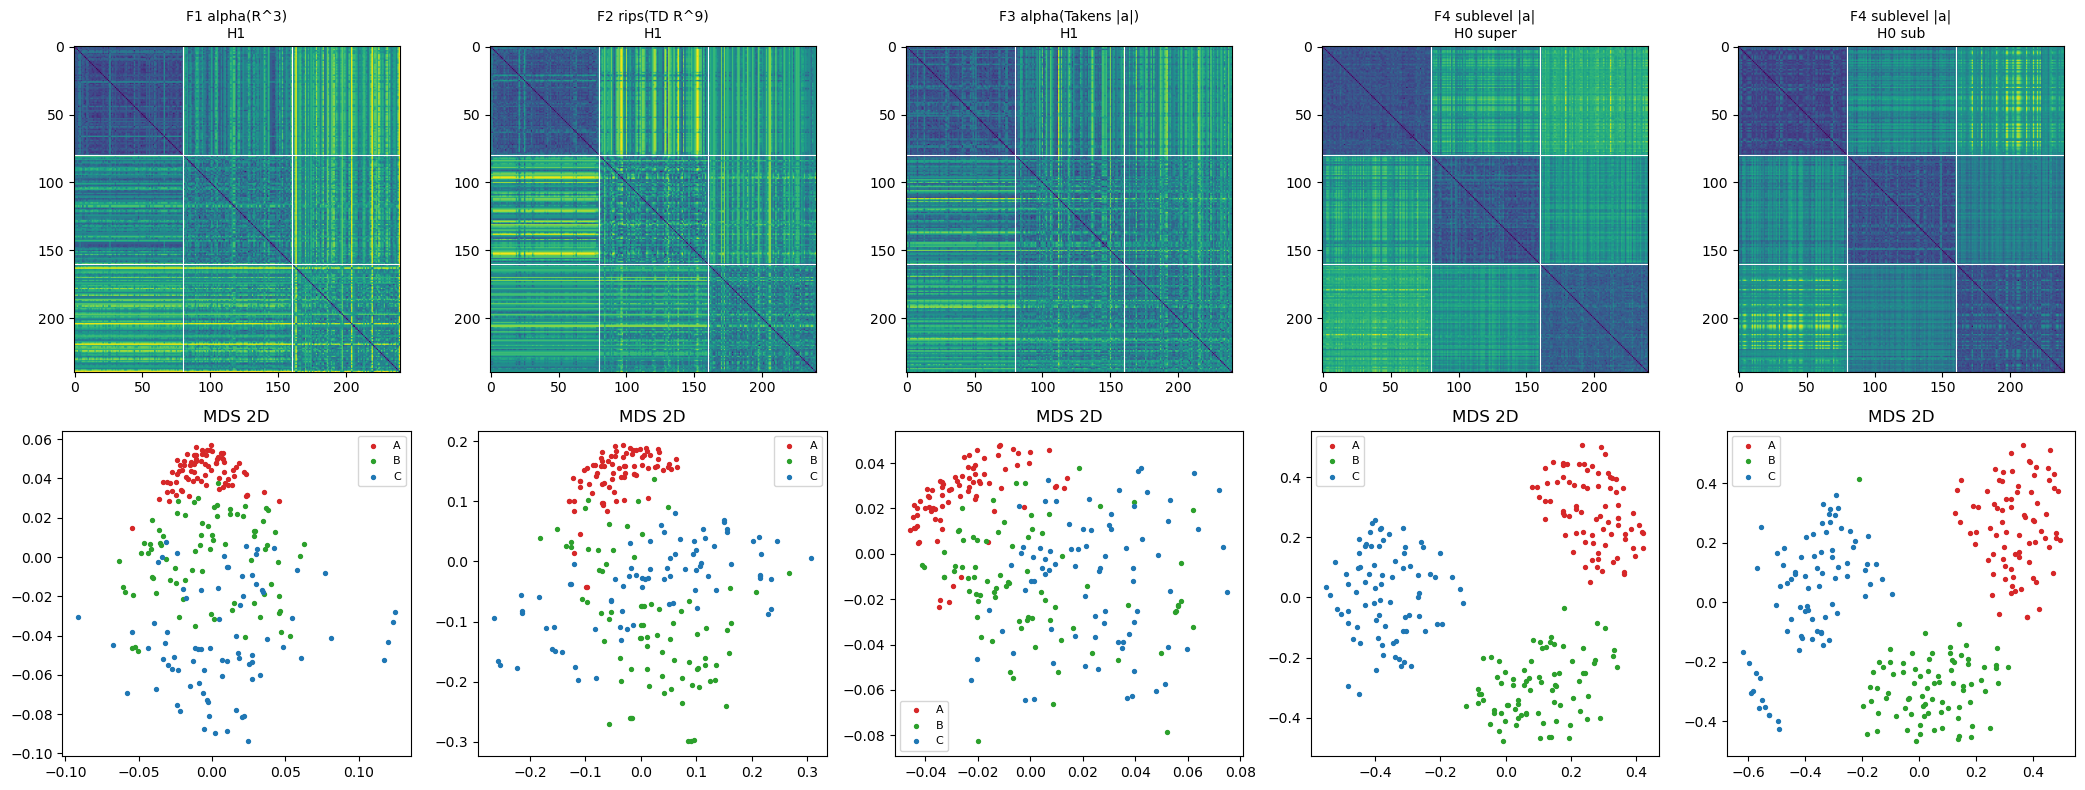

In [11]:
fig, axes = plt.subplots(2, len(BMAT), figsize=(4.2 * len(BMAT), 8))
for j, ((name, k), B) in enumerate(BMAT.items()):
    dims = FILTRATIONS[name][1]
    axes[0, j].imshow(B, cmap="viridis"); axes[0, j].set_title(f"{name}\n{dims[k]}", fontsize=10)
    for t in (80, 160): axes[0, j].axhline(t, c="w", lw=.8); axes[0, j].axvline(t, c="w", lw=.8)
    pos = manifold.MDS(2, dissimilarity="precomputed", random_state=0, n_init=2).fit_transform(B)
    for c in "ABC": axes[1, j].scatter(*pos[y == c].T, s=8, c=COL[c], label=c)
    axes[1, j].legend(fontsize=8); axes[1, j].set_title("MDS 2D")
plt.tight_layout(); plt.show()

**Interpretation.** The block structure (A | B | C) in the matrices and the clusters in MDS show which filtrations separate the persons.
The bottleneck distance only looks at the *single worst* matched point, so it is a rather coarse summary; a classifier on vectorized
diagrams can exploit the *whole* diagram. Typically:
* **F4** (valleys and peaks of $\|a\|$): three clean diagonal blocks and three well separated clusters in MDS → the most discriminative filtration.
* **$H_1$ of F1/F2/F3**: person A forms a compact cluster (very regular gait loop), while B and C overlap → loops alone do not separate B from C.

# 4. Vectorization

Classifiers need vectors. We use four maps from diagrams to $\mathbb{R}^d$ (all `fit` on the training set only):

* **Statistics**: number of points, total / max / mean persistence, persistence entropy $-\sum p_i\log p_i$ with $p_i=\ell_i/\sum\ell_j$, top-3 persistences.
* **Persistence landscapes** $\lambda_k(t)=k$-th largest value of $\max(0,\min(t-b,d-t))$: stable, invertible; we keep $k\le5$ sampled at 100 points.
* **Persistence silhouette** $\phi(t)=\sum_i w_i\Lambda_i(t)/\sum_i w_i$ with weights $w_i=(d_i-b_i)$: one weighted average curve, emphasises persistent points.
* **Persistence image**: diagram in (birth, persistence) coordinates, each point replaced by a Gaussian of width $\sigma$, weighted by persistence, integrated on a 20×20 grid.

In [12]:
class DimSelect(BaseEstimator, TransformerMixin):
    # pick the k-th diagram (homology dimension) from each sample's list of diagrams
    def __init__(self, k=0): self.k = k
    def fit(self, D, y=None): return self
    def transform(self, D): return [d[self.k] for d in D]

class DiagStats(BaseEstimator, TransformerMixin):
    def fit(self, D, y=None): return self
    def transform(self, D):
        out = []
        for d in D:
            l = d[:, 1] - d[:, 0]
            if len(l) == 0: out.append(np.zeros(8)); continue
            p = l / l.sum(); top = np.sort(l)[::-1][:3]
            out.append(np.r_[len(l), l.sum(), l.max(), l.mean(), -(p * np.log(p + 1e-12)).sum(), np.pad(top, (0, 3 - len(top)))])
        return np.array(out)

def pers_weight(x): return x[1] - x[0]
def pi_weight(x): return x[1]          # after BirthPersistenceTransform, x[1] is persistence

def make_vectorizer(kind):
    if kind == "stats": return DiagStats()
    if kind == "betti": return gdr.BettiCurve(resolution=100)
    if kind == "landscape": return gdr.Landscape(num_landscapes=5, resolution=100)
    if kind == "silhouette": return gdr.Silhouette(weight=pers_weight, resolution=100)
    if kind == "pimage": return make_pipeline(gdr.BirthPersistenceTransform(),
                                              gdr.PersistenceImage(bandwidth=0.05, weight=pi_weight, resolution=[20, 20]))

def make_features(kind, n_dims):
    return make_union(*[make_pipeline(DimSelect(k), gdr.DiagramSelector(use=True, point_type="finite"),
                                      make_vectorizer(kind)) for k in range(n_dims)])

**What the vectorization sees.** Mean silhouette of the *peak diagram* of F4 for each person, and the mean persistence image of $H_1$ of F1.
Differences between the class-averages are what the classifier will use.

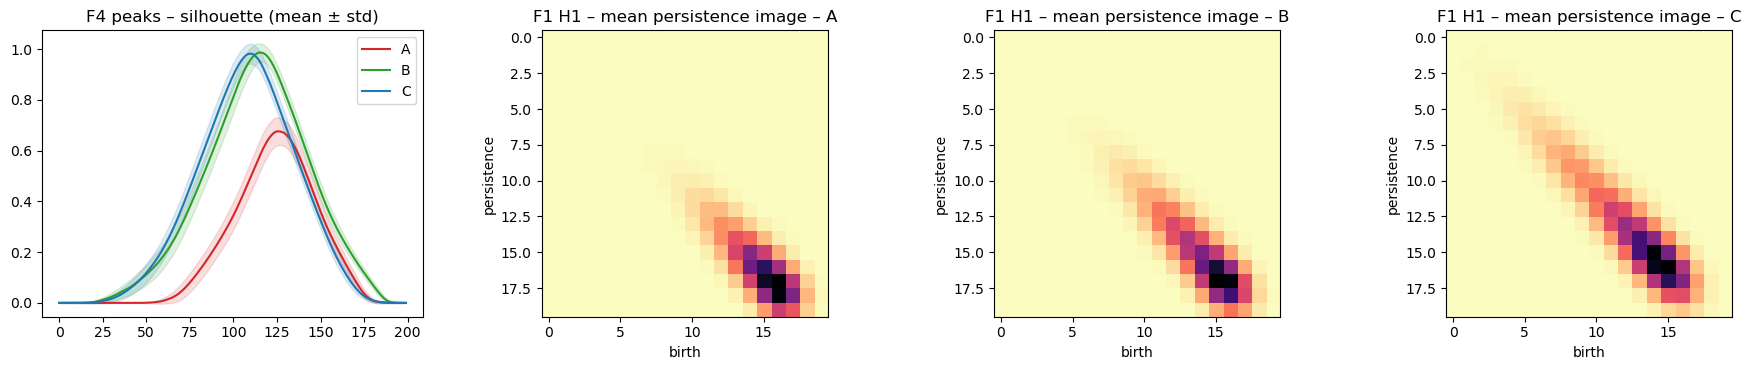

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
sil = make_pipeline(DimSelect(1), gdr.DiagramSelector(use=True), gdr.Silhouette(weight=pers_weight, resolution=200)).fit(train_diags["F4 sublevel |a|"])
S = sil.transform(train_diags["F4 sublevel |a|"])
for c in "ABC":
    m, sd = S[y == c].mean(0), S[y == c].std(0)
    ax[0].plot(m, c=COL[c], label=c); ax[0].fill_between(range(len(m)), m - sd, m + sd, color=COL[c], alpha=.15)
ax[0].set_title("F4 peaks – silhouette (mean ± std)"); ax[0].legend()
pim = make_pipeline(DimSelect(1), gdr.DiagramSelector(use=True), make_vectorizer("pimage")).fit(train_diags["F1 alpha(R^3)"])
P = pim.transform(train_diags["F1 alpha(R^3)"])
for j, c in enumerate("ABC"):
    ax[j + 1].imshow(np.flipud(P[y == c].mean(0).reshape(20, 20).T), cmap="magma")
    ax[j + 1].set_title(f"F1 H1 – mean persistence image – {c}"); ax[j + 1].set_xlabel("birth"); ax[j + 1].set_ylabel("persistence")
plt.tight_layout(); plt.show()

**Exploring a hyperparameter interactively** (Question 5). Slider over the bandwidth $\sigma$ of the persistence image:
too small → the image is a set of isolated spikes (unstable, sensitive to noise); too large → everything is blurred into one blob.

In [14]:
import plotly.graph_objs as go
d_sel = train_diags["F1 alpha(R^3)"][reps["A"]][1]
d_bp = gdr.BirthPersistenceTransform().fit_transform([d_sel])
rng = [d_bp[0][:, 0].min(), d_bp[0][:, 0].max(), 0, d_bp[0][:, 1].max()]
bws = np.round(np.logspace(-3, -0.5, 10), 4)
fig = go.Figure()
for i, bw in enumerate(bws):
    img = gdr.PersistenceImage(bandwidth=bw, weight=pi_weight, resolution=[40, 40], im_range=rng).fit_transform(d_bp)[0]
    fig.add_trace(go.Heatmap(z=img.reshape(40, 40).T, colorscale="magma", visible=(i == 0), showscale=False))
steps = [dict(method="update", args=[{"visible": [j == i for j in range(len(bws))]}], label=str(bw)) for i, bw in enumerate(bws)]
fig.update_layout(sliders=[dict(steps=steps, currentvalue={"prefix": "bandwidth σ = "})], height=450,
                  title="Persistence image of one H1 diagram (F1) vs bandwidth", xaxis_title="birth", yaxis_title="persistence")
fig.show()

# 5. Classification – systematic comparison

Pipeline (Question 6) = `[select homology dim → keep finite points → vectorize] for each dim` → concatenate → classifier.

Classifiers:
* **Random forest**: average of many decision trees trained on bootstrap samples with random feature subsets; robust to feature scale and to many uninformative features, gives feature importances.
* **SVM (RBF kernel)** on standardized features: maximum-margin separator in the feature space of the Gaussian kernel $k(x,x')=e^{-\gamma\|x-x'\|^2}$.

For each of the 4 × 4 × 2 = 32 pipelines we report the random 5-fold accuracy and the blocked & purged 5-fold accuracy.

In [15]:
CLASSIFIERS = {"RF": lambda: RandomForestClassifier(n_estimators=500, random_state=0),
               "SVM": lambda: make_pipeline(StandardScaler(), SVC(C=10, gamma="scale"))}
VECS = ["stats", "landscape", "silhouette", "pimage"]

def build(filt, vec, clf):
    return make_pipeline(make_features(vec, len(FILTRATIONS[filt][1])), CLASSIFIERS[clf]())

rows = []
for filt in FILTRATIONS:
    D = train_diags[filt]
    for vec in VECS:
        for clf in CLASSIFIERS:
            r = cross_val_score(build(filt, vec, clf), D, y, cv=random_cv).mean()
            b = cross_val_score(build(filt, vec, clf), D, y, cv=list(blocked_purged_splits())).mean()
            rows.append(dict(filtration=filt, vectorization=vec, classifier=clf, random_cv=r, blocked_cv=b))
results = pd.DataFrame(rows)
results.sort_values("blocked_cv", ascending=False).head(12).style.format({"random_cv": "{:.3f}", "blocked_cv": "{:.3f}"})

,filtration,vectorization,classifier,random_cv,blocked_cv
30,F4 sublevel |a|,pimage,RF,1.000,1.000
28,F4 sublevel |a|,silhouette,RF,1.000,1.000
25,F4 sublevel |a|,stats,SVM,1.000,1.000
24,F4 sublevel |a|,stats,RF,1.000,1.000
0,F1 alpha(R^3),stats,RF,0.996,0.996
27,F4 sublevel |a|,landscape,SVM,1.000,0.996
20,F3 alpha(Takens |a|),silhouette,RF,0.996,0.996
26,F4 sublevel |a|,landscape,RF,1.000,0.996
29,F4 sublevel |a|,silhouette,SVM,1.000,0.995
6,F1 alpha(R^3),pimage,RF,0.996,0.993


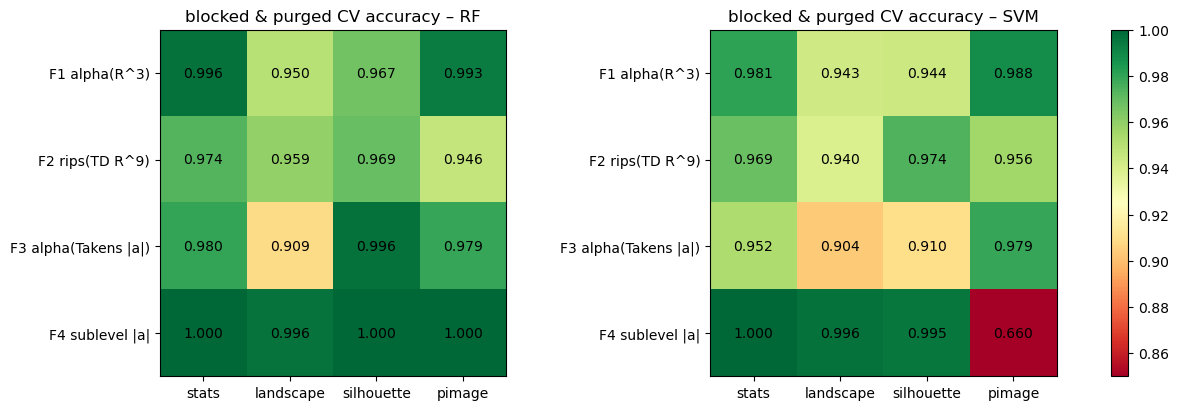

mean drop random -> blocked CV: 0.025


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, clf in zip(axes, CLASSIFIERS):
    T = results[results.classifier == clf].pivot(index="filtration", columns="vectorization", values="blocked_cv")[VECS]
    im = ax.imshow(T.values, cmap="RdYlGn", vmin=0.85, vmax=1)
    ax.set_xticks(range(len(VECS))); ax.set_xticklabels(VECS); ax.set_yticks(range(len(T))); ax.set_yticklabels(T.index)
    for i in range(T.shape[0]):
        for j in range(T.shape[1]): ax.text(j, i, f"{T.values[i, j]:.3f}", ha="center", va="center")
    ax.set_title(f"blocked & purged CV accuracy – {clf}")
plt.colorbar(im, ax=axes, fraction=.02); plt.show()
print("mean drop random -> blocked CV:", round((results.random_cv - results.blocked_cv).mean(), 3))

**Analysis.**
* All filtrations carry information on the walker (most accuracies > 90 %), but **F4 – sub/superlevel filtration of $\|a(t)\|$** is the most reliable,
  for all vectorizations. It is also the cheapest (a filtration on a path graph with 200 vertices) and is rotation invariant.
* Random K-fold is **optimistic** because of the overlap between windows; the blocked CV lowers several scores (most visibly for
  landscapes + SVM), which is what we should trust.
* Random forests are more robust than the SVM here: the landscape/image vectors are high dimensional with many near-zero coordinates;
  RF selects the informative ones automatically, while the RBF-SVM treats all coordinates equally.
* F2 (Rips on the 9D delay embedding) is ~50× slower than the others without being better.

# 5b. Vectorizations × classifiers – extended comparison

We now compare **6 representations of the diagrams** and **5 classifiers** on the 4 filtrations, all under the blocked & purged CV
(the featurizer is re-fitted on each training fold).

| Vectorization | Definition | Comment |
|---|---|---|
| statistics | #points, total/max/mean persistence, entropy, top-3 persistences | 8 numbers per diagram, interpretable |
| Betti curve | $\beta(t)=\#\{(b,d): b\le t<d\}$ on a grid | simplest functional summary, not stable for the bottleneck distance |
| landscape | $\lambda_k(t)$, $k\le5$ | stable, 500 numbers per diagram |
| silhouette | persistence-weighted mean of the tent functions | stable, 100 numbers |
| persistence image | Gaussian smoothing in (birth, persistence), 20×20 | stable, 400 numbers |
| **sliced Wasserstein kernel** | $k(D,D')=\exp(-SW(D,D')/\sigma)$, $SW$ = average over directions of the 1D Wasserstein distance of the projected diagrams | a *kernel*, no explicit vector: used with a kernel-SVM (and $SW$ with k-NN) |

| Classifier | Idea |
|---|---|
| Random forest | many decorrelated decision trees, majority vote |
| Gradient boosting | trees added sequentially, each one corrects the errors of the previous ones |
| SVM (RBF) | maximum margin separator in the feature space of a Gaussian kernel |
| Logistic regression | linear model, multinomial soft-max |
| k-NN ($k=5$) | majority label of the 5 nearest training points |

In [17]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import silhouette_score

CLASSIFIERS2 = {
    "RF": lambda: RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=-1),
    "GradBoost": lambda: HistGradientBoostingClassifier(random_state=0),
    "SVM-RBF": lambda: make_pipeline(StandardScaler(), SVC(C=10, gamma="scale")),
    "LogReg": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "kNN": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(5)),
}
VECS2 = ["stats", "betti", "landscape", "silhouette", "pimage"]
SPLITS = list(blocked_purged_splits())

rows2 = []
for filt, (_, dims) in FILTRATIONS.items():
    D = train_diags[filt]; t0 = time.time()
    for vec in VECS2:
        acc = {c: [] for c in CLASSIFIERS2}
        for tr, te in SPLITS:
            feat = make_features(vec, len(dims)).fit([D[i] for i in tr])
            Ftr, Fte = feat.transform([D[i] for i in tr]), feat.transform([D[i] for i in te])
            for c, mk in CLASSIFIERS2.items():
                acc[c].append((mk().fit(Ftr, y[tr]).predict(Fte) == y[te]).mean())
        for c in CLASSIFIERS2:
            rows2.append(dict(filtration=filt, vectorization=vec, classifier=c, blocked_cv=np.mean(acc[c])))
    print(f"{filt:22s} done in {time.time() - t0:.0f}s")

F1 alpha(R^3)          done in 110s
F2 rips(TD R^9)        done in 109s
F3 alpha(Takens |a|)   done in 115s
F4 sublevel |a|        done in 96s


In [18]:
# Sliced Wasserstein distances between all diagrams (train + eval), one matrix per homology dimension
SWD = {}
for filt, (_, dims) in FILTRATIONS.items():
    cache = f"cache_SW_{filt.split()[0]}.pkl"
    if os.path.exists(cache): SWD[filt] = pickle.load(open(cache, "rb")); continue
    t0 = time.time(); SWD[filt] = []
    for k in range(len(dims)):
        Dk = gdr.DiagramSelector(use=True).fit_transform([d[k] for d in DIAGS[filt]])
        SWD[filt].append(gdr.SlicedWassersteinDistance(num_directions=20).fit(Dk).transform(Dk))
    pickle.dump(SWD[filt], open(cache, "wb")); print(f"{filt:22s} SW distances {time.time() - t0:.0f}s")

def sw_kernel_eval(filt):
    acc_svm, acc_knn = [], []
    for tr, te in SPLITS:
        # bandwidth = median SW distance on the training fold, kernels of the homology dimensions are averaged
        K = np.mean([np.exp(-S[:240, :240] / np.median(S[np.ix_(tr, tr)])) for S in SWD[filt]], axis=0)
        Dsum = np.sum([S[:240, :240] / np.median(S[np.ix_(tr, tr)]) for S in SWD[filt]], axis=0)
        svm = SVC(kernel="precomputed", C=10).fit(K[np.ix_(tr, tr)], y[tr])
        acc_svm.append((svm.predict(K[np.ix_(te, tr)]) == y[te]).mean())
        knn = KNeighborsClassifier(5, metric="precomputed").fit(Dsum[np.ix_(tr, tr)], y[tr])
        acc_knn.append((knn.predict(Dsum[np.ix_(te, tr)]) == y[te]).mean())
    return np.mean(acc_svm), np.mean(acc_knn)

for filt in FILTRATIONS:
    s, k = sw_kernel_eval(filt)
    rows2 += [dict(filtration=filt, vectorization="SW kernel", classifier="SVM-RBF", blocked_cv=s),
              dict(filtration=filt, vectorization="SW kernel", classifier="kNN", blocked_cv=k)]
results2 = pd.DataFrame(rows2)

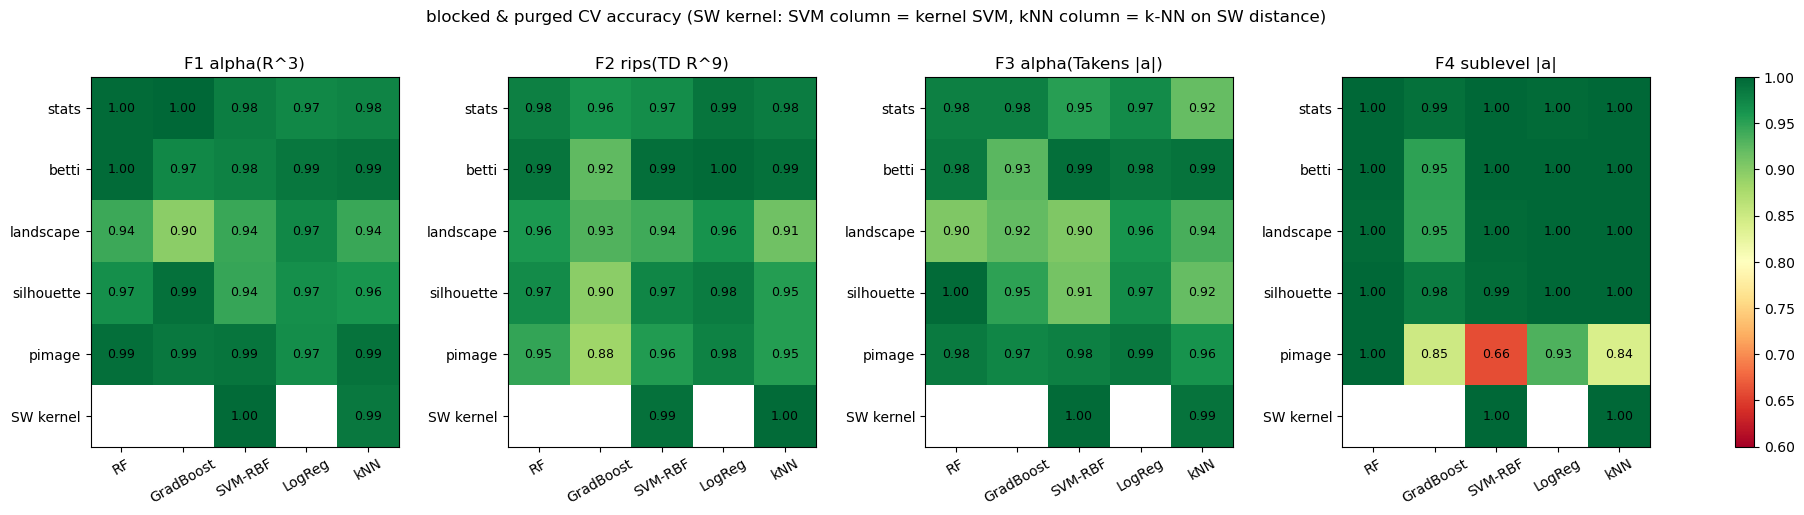

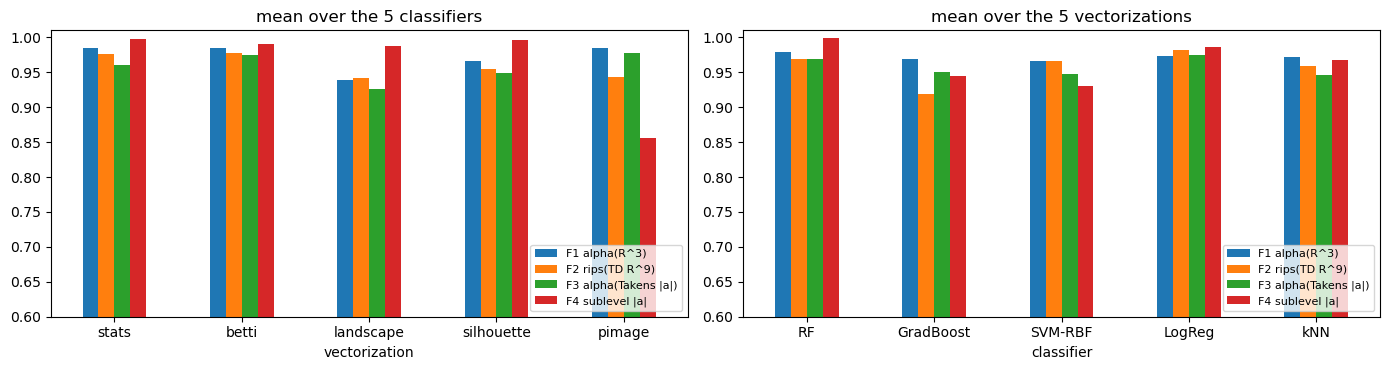

In [19]:
VROWS = VECS2 + ["SW kernel"]; CCOLS = list(CLASSIFIERS2)
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))
for ax, filt in zip(axes, FILTRATIONS):
    T = results2[results2.filtration == filt].pivot(index="vectorization", columns="classifier", values="blocked_cv").reindex(index=VROWS, columns=CCOLS)
    im = ax.imshow(T.values, cmap="RdYlGn", vmin=0.6, vmax=1)
    ax.set_xticks(range(len(CCOLS))); ax.set_xticklabels(CCOLS, rotation=30); ax.set_yticks(range(len(VROWS))); ax.set_yticklabels(VROWS)
    for i in range(T.shape[0]):
        for j in range(T.shape[1]):
            if not np.isnan(T.values[i, j]): ax.text(j, i, f"{T.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(filt)
plt.colorbar(im, ax=axes, fraction=.012); plt.suptitle("blocked & purged CV accuracy (SW kernel: SVM column = kernel SVM, kNN column = k-NN on SW distance)", y=1.02)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
r = results2[results2.vectorization != "SW kernel"]
r.pivot_table(index="vectorization", columns="filtration", values="blocked_cv").reindex(VECS2).plot.bar(ax=ax[0], rot=0)
ax[0].set_ylim(.6, 1.01); ax[0].set_title("mean over the 5 classifiers"); ax[0].legend(fontsize=8, loc="lower right")
r.pivot_table(index="classifier", columns="filtration", values="blocked_cv").reindex(CCOLS).plot.bar(ax=ax[1], rot=0)
ax[1].set_ylim(.6, 1.01); ax[1].set_title("mean over the 5 vectorizations"); ax[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()


**Analysis (5b).**
* **The filtration matters more than the vectorization or the classifier**: F4 reaches ≥ 0.99 for almost every combination; F1–F3 range over 0.88–1.00.
* **Vectorizations.** Simple statistics and Betti curves are as good as the sophisticated representations here: the person-specific information is in *global* quantities (how much persistence there is), not in the fine geometry of the diagrams.
  Landscapes are the weakest on average: they keep only the $k=5$ largest tent functions. For $H_0$ diagrams whose births are all 0, the information is in the *bulk* of small features, which landscapes discard (see Section 7.1: Alpha $H_0$ + landscape 0.67 vs + silhouette 0.97).
* **Interaction vectorization × classifier**: persistence image + RBF-SVM fails on F4 (0.66) while the same features with a random forest give 1.00 — with a fixed bandwidth the 800-dimensional image vectors are very sparse and the RBF kernel distances become uninformative.
* **Classifiers.** Random forests are the most robust (mean 0.97–1.00 over vectorizations); gradient boosting and the RBF-SVM are the most sensitive to the representation.
  The **sliced-Wasserstein kernel** + SVM reaches 0.99–1.00 on all four filtrations: a kernel defined directly on diagrams avoids choosing a vectorization.


# 5c. Question 4 revisited – bottleneck vs Wasserstein distances

For two diagrams $D,D'$ (diagonal points allowed in the matchings $\gamma$):
$$d_B(D,D')=\inf_\gamma\sup_{x\in D}\|x-\gamma(x)\|_\infty ,\qquad
W_p(D,D')=\Big(\inf_\gamma\sum_{x\in D}\|x-\gamma(x)\|_2^{\,p}\Big)^{1/p}.$$
* the **bottleneck** distance only sees the *worst* matched point: it is driven by the most persistent features; very robust but it ignores the rest of the diagram;
* the **Wasserstein** distance *sums* over all points: it uses the whole diagram (many medium-size features also count); $W_1$ weights all points linearly, $W_2$ emphasises the large displacements; $W_\infty=d_B$.

We compare $d_B$, $W_1$, $W_2$ on the Q4 construction (Rips on the delay embedding in $\mathbb{R}^9$, $H_0$ and $H_1$) and on F4.
Quantitative criteria: **k-NN accuracy** using the distance directly (blocked CV) and the **silhouette score**
$s=\frac{1}{n}\sum_i\frac{b_i-a_i}{\max(a_i,b_i)}$ ($a_i$: mean distance to its own class, $b_i$: to the nearest other class; $s\in[-1,1]$).

In [20]:
DIST_ITEMS = [("F2 rips(TD R^9)", 0), ("F2 rips(TD R^9)", 1), ("F4 sublevel |a|", 0), ("F4 sublevel |a|", 1)]
METRICS = ["bottleneck", "W1", "W2"]
DM = {}
for name, k in DIST_ITEMS:
    for met in METRICS:
        cache = f"cache_dist_{name.split()[0]}_{k}_{met}.pkl"
        if os.path.exists(cache): DM[(name, k, met)] = pickle.load(open(cache, "rb")); continue
        t0 = time.time(); DM[(name, k, met)] = tda_utils.distance_matrix([d[k] for d in train_diags[name]], met)
        pickle.dump(DM[(name, k, met)], open(cache, "wb")); print(name, k, met, f"{time.time() - t0:.0f}s")

def knn_blocked(Dm, k=5):
    return np.mean([(KNeighborsClassifier(k, metric="precomputed").fit(Dm[np.ix_(tr, tr)], y[tr]).predict(Dm[np.ix_(te, tr)]) == y[te]).mean()
                    for tr, te in SPLITS])

rows3 = []
for (name, k, met), Dm in DM.items():
    rows3.append(dict(diagram=f"{name} – {FILTRATIONS[name][1][k]}", metric=met,
                      knn_blocked_cv=knn_blocked(Dm), silhouette=silhouette_score(Dm, y, metric="precomputed")))
dist_table = pd.DataFrame(rows3).pivot(index="diagram", columns="metric")
dist_table.style.format("{:.3f}").background_gradient(cmap="RdYlGn", axis=None)

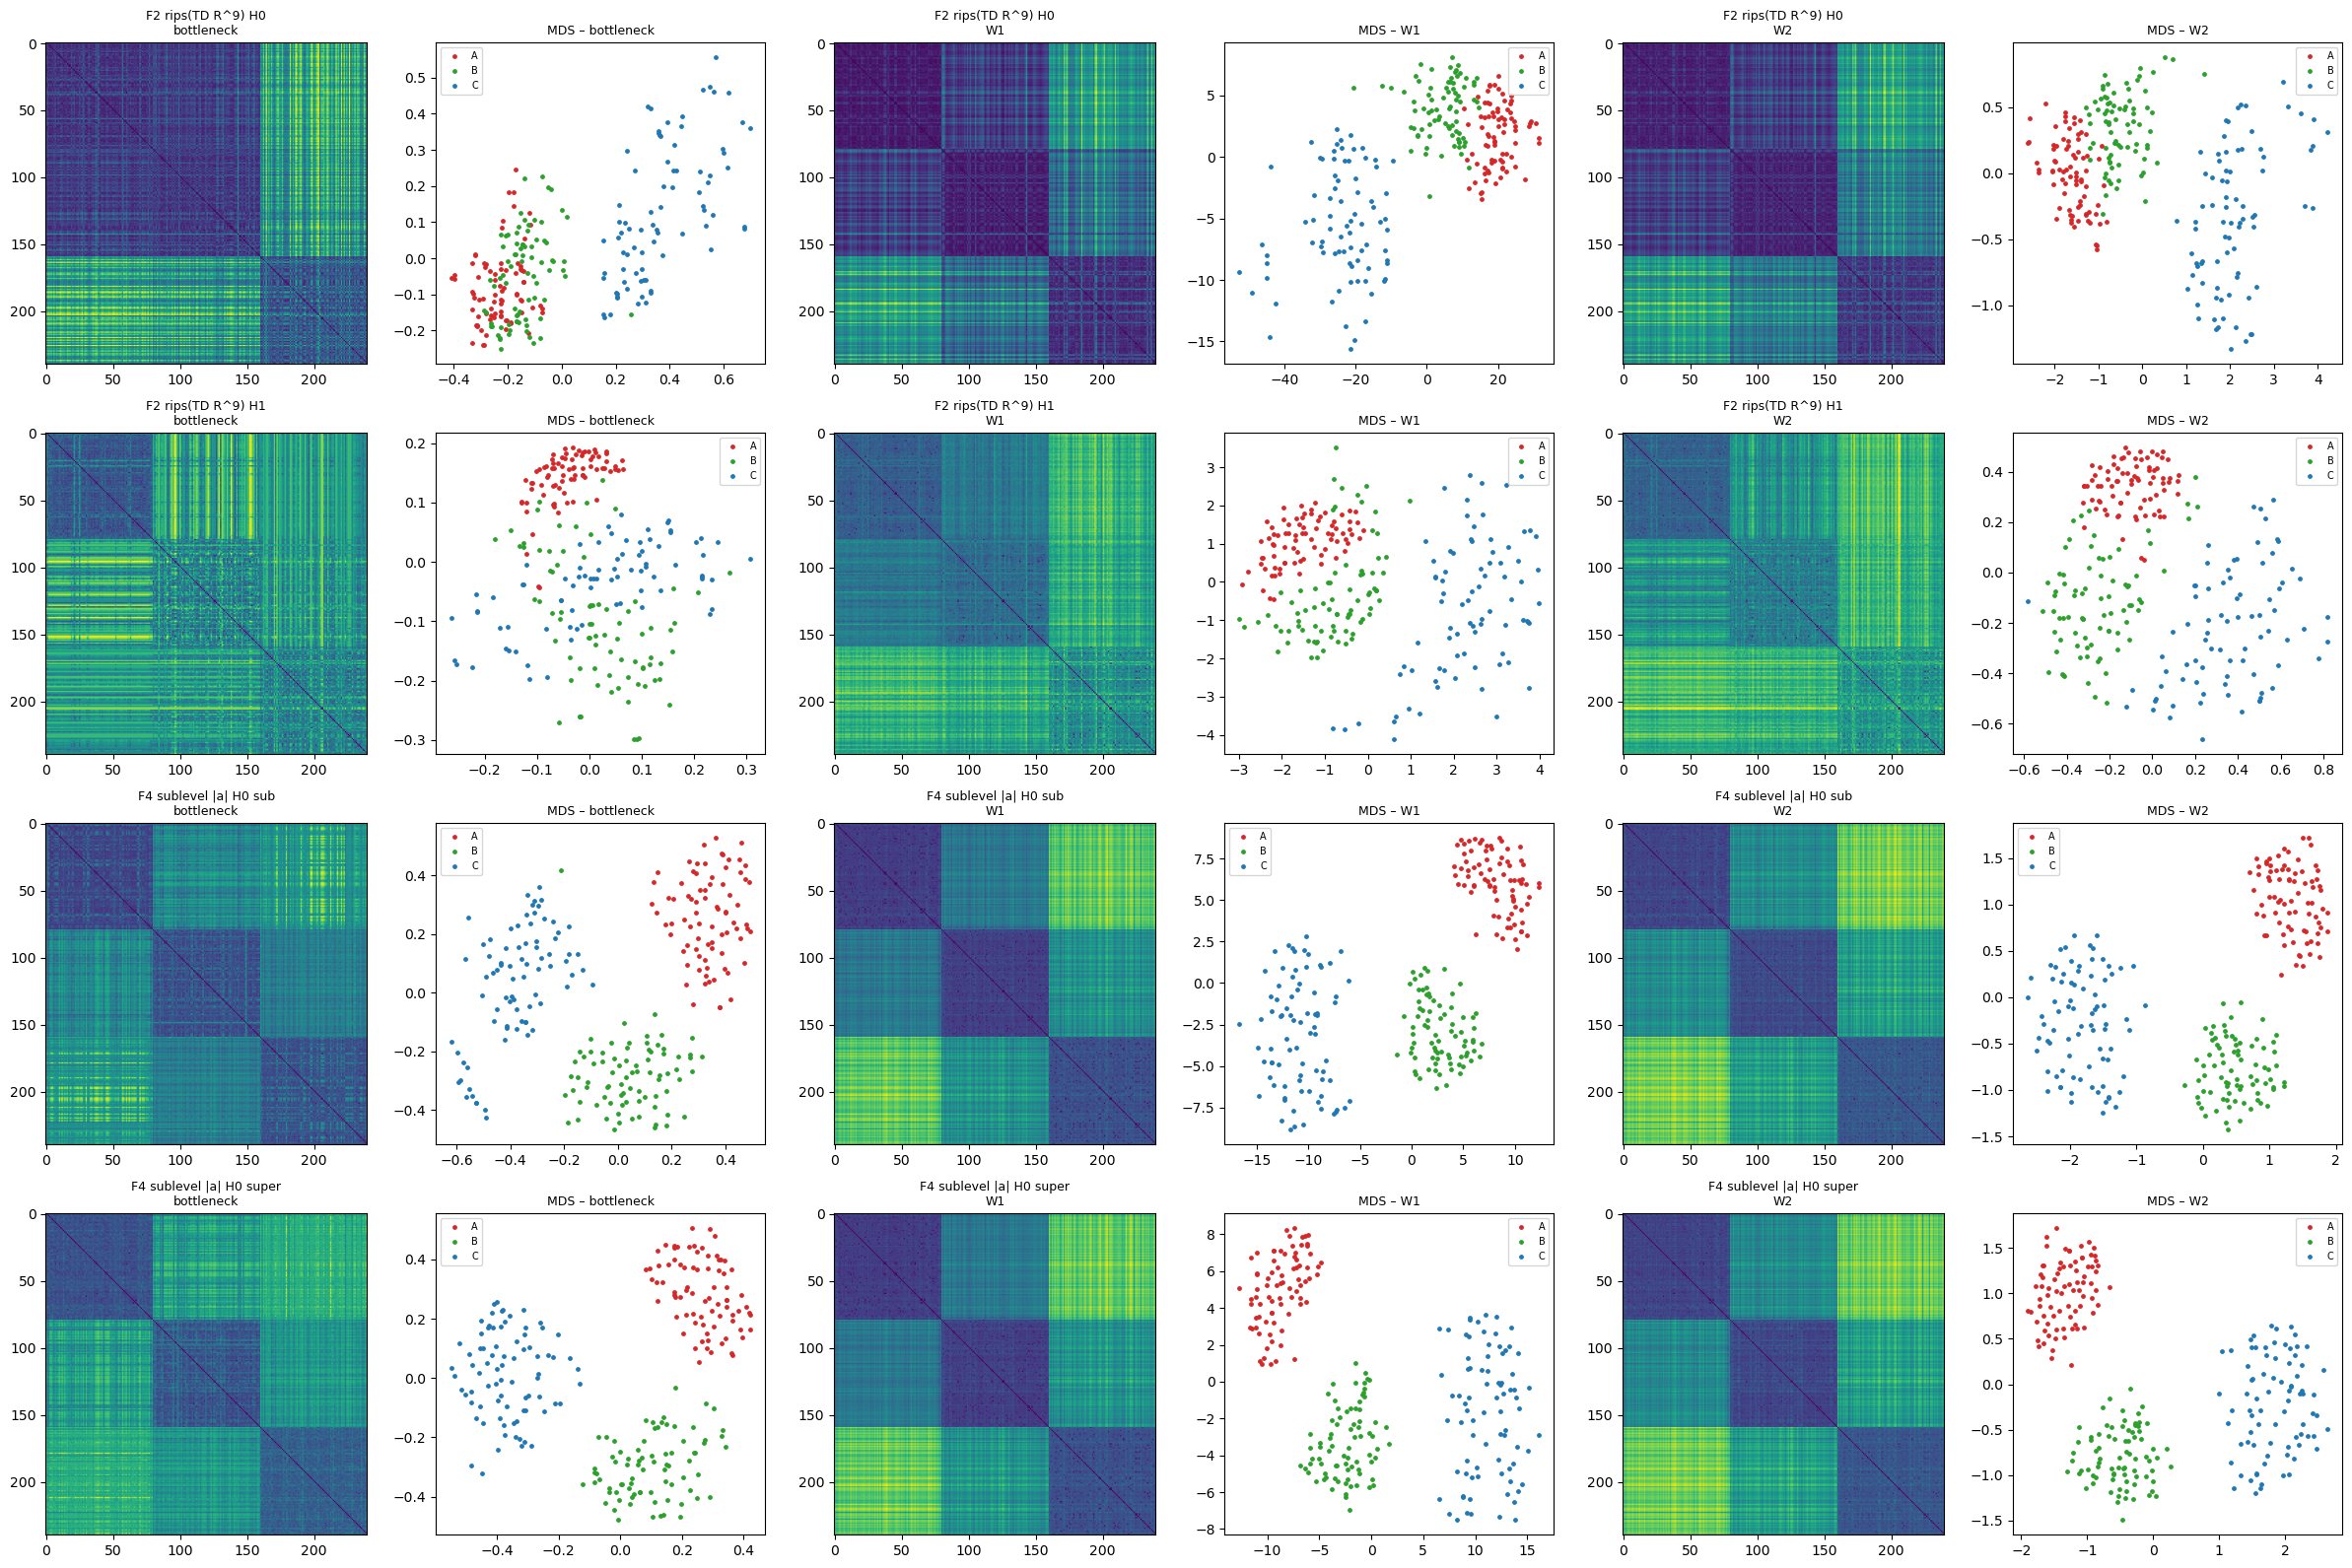

In [21]:
fig, axes = plt.subplots(len(DIST_ITEMS), 6, figsize=(24, 4 * len(DIST_ITEMS)))
for r, (name, k) in enumerate(DIST_ITEMS):
    for j, met in enumerate(METRICS):
        Dm = DM[(name, k, met)]
        axes[r, 2 * j].imshow(Dm, cmap="viridis"); axes[r, 2 * j].set_title(f"{name} {FILTRATIONS[name][1][k]}\n{met}", fontsize=9)
        pos = manifold.MDS(2, dissimilarity="precomputed", random_state=0, n_init=2).fit_transform(Dm)
        for c in "ABC": axes[r, 2 * j + 1].scatter(*pos[y == c].T, s=6, c=COL[c], label=c)
        axes[r, 2 * j + 1].set_title(f"MDS – {met}", fontsize=9); axes[r, 2 * j + 1].legend(fontsize=7)
plt.tight_layout(); plt.show()


**Analysis (5c).**

| diagram | k-NN accuracy: $d_B$ / $W_1$ / $W_2$ | silhouette: $d_B$ / $W_1$ / $W_2$ |
|---|---|---|
| Rips (delay $\mathbb{R}^9$) $H_0$ | 0.848 / **0.954** / 0.946 | 0.21 / **0.50** / 0.45 |
| Rips (delay $\mathbb{R}^9$) $H_1$ | 0.894 / **0.949** / 0.943 | 0.20 / 0.18 / **0.23** |
| F4 valleys | 0.990 / **1.000** / **1.000** | 0.39 / 0.52 / **0.53** |
| F4 peaks | **1.000** / **1.000** / **1.000** | 0.45 / 0.53 / **0.54** |

* **Wasserstein separates the persons better than bottleneck in every case**, most clearly for $H_0$ (k-NN 0.85 → 0.95, silhouette 0.21 → 0.50).
  The bottleneck distance only sees the single worst-matched point; the class information in $H_0$ is spread over *many* small features (the gap distribution), which only a sum over all points ($W_p$) captures. Same conclusion as Track A for the Alpha $H_0$ diagrams.
* $W_1$ and $W_2$ behave similarly. The bottleneck has the stronger stability guarantee ($\|\cdot\|_\infty$), Wasserstein is more discriminative here.
* Cost: $W_p$ on $H_0$ diagrams with ~200 points is 10–15× slower than the bottleneck.


# 5d. Time-delay embedding: dimension $m$, delay $\tau$ and time window

For a series $a(t)\in\mathbb{R}^3$ the delay embedding is $\Phi(t)=(a(t),a(t+\tau),\dots,a(t+(m-1)\tau))\in\mathbb{R}^{3m}$.
Each point of the cloud summarises a **time window of length $L=(m-1)\tau+1$ samples**.
By Takens' theorem, a periodic motion becomes a **closed curve** in the embedding, i.e. a persistent $H_1$ class.

*Practical warning (gudhi).* For a vector-valued series, `TimeDelayEmbedding(dim=...)` takes the **total** dimension $3m$, and `dim=3` returns the raw
series unchanged. The code given with Question 4 uses `dim=9, delay=1` while the text asks for delay 2; we use $m=3,\tau=2$ (`dim=9, delay=2`).

**Which window?** The natural time scale is the gait period $T$. We estimate it from the autocorrelation of $\|a(t)\|$:

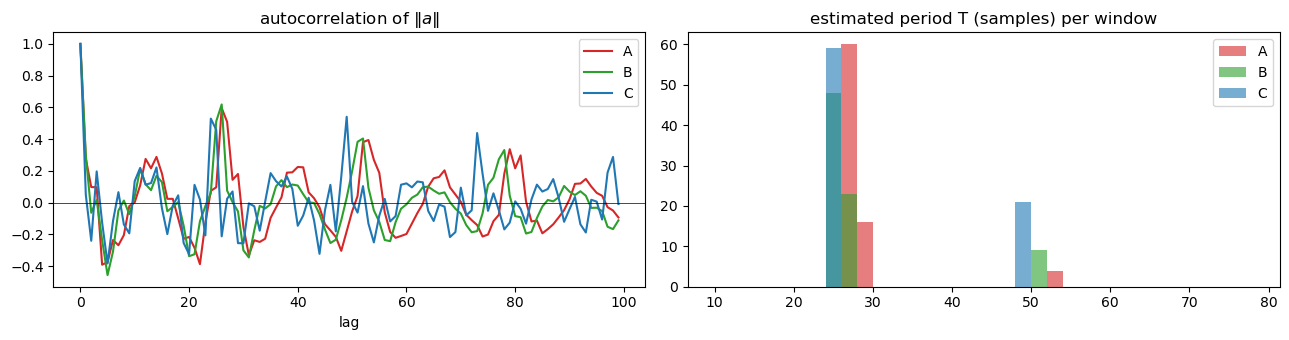

median period: {'A': 27, 'B': 25, 'C': 25}


In [22]:
def gait_period(w, tmin=10):
    s = np.linalg.norm(w, axis=1); s = s - s.mean()
    ac = np.correlate(s, s, "full")[len(s) - 1:]; ac /= ac[0]
    return tmin + np.argmax(ac[tmin:100])           # first strong peak after lag 10

per = np.array([gait_period(w) for w in X])
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
for c in "ABC":
    s = np.linalg.norm(X[np.where(y == c)[0][0]], axis=1); s = s - s.mean()
    ac = np.correlate(s, s, "full")[199:]; ax[0].plot(ac[:100] / ac[0], c=COL[c], label=c)
    ax[1].hist(per[y == c], bins=range(10, 80, 2), alpha=.6, color=COL[c], label=c)
ax[0].set_title(r"autocorrelation of $\|a\|$"); ax[0].set_xlabel("lag"); ax[0].legend(); ax[0].axhline(0, c="k", lw=.5)
ax[1].set_title("estimated period T (samples) per window"); ax[1].legend(); plt.tight_layout(); plt.show()
T_med = {c: int(np.median(per[y == c])) for c in "ABC"}; print("median period:", T_med)

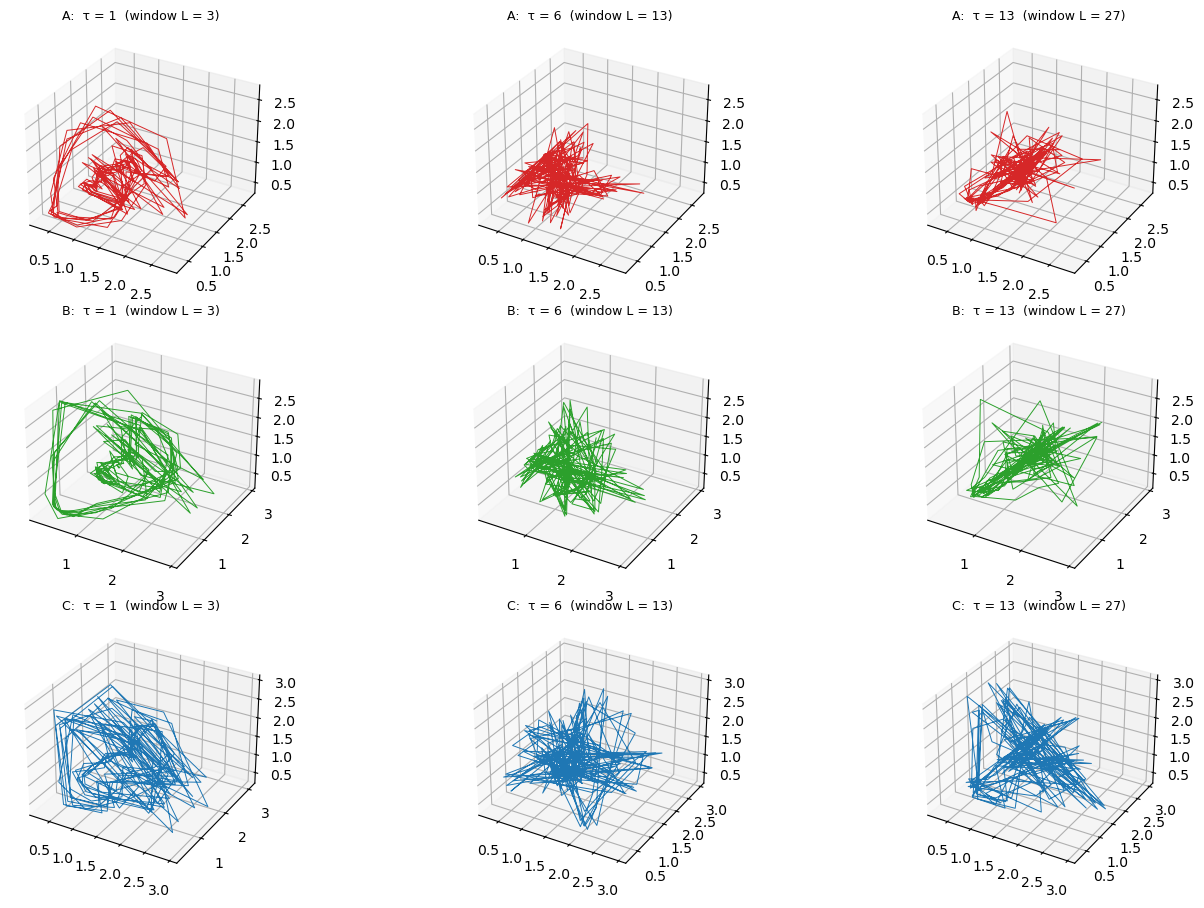

In [23]:
# what the delay does: Takens embedding of |a(t)| in R^3 for one window of each person and 3 delays
T0 = int(np.median(per))
taus = [1, max(1, T0 // 4), T0 // 2]
fig = plt.figure(figsize=(15, 9))
for r, c in enumerate("ABC"):
    s = np.linalg.norm(X[np.where(y == c)[0][0]], axis=1)
    for j, tau in enumerate(taus):
        pc = TimeDelayEmbedding(dim=3, delay=tau)(s)
        ax = fig.add_subplot(3, 3, 3 * r + j + 1, projection="3d"); ax.plot(*pc.T, c=COL[c], lw=.7)
        ax.set_title(f"{c}:  τ = {tau}  (window L = {2 * tau + 1})", fontsize=9)
plt.tight_layout(); plt.show()


*Expected behaviour for a sinusoidal signal* (checked below on the real data):
* $\tau=1$: consecutive values almost equal → cloud squeezed along the diagonal;
* $\tau\approx T/4$: decorrelated coordinates → round loop, maximal $H_1$ persistence;
* $\tau\approx T$: $s(t+\tau)\approx s(t)$ → the curve collapses back onto the diagonal.

### Parameter sweep
**(a)** Multivariate embedding of $a(t)$, Rips filtration, $m\in\{1,2,3,4\}$, $\tau\in\{1,2,4,8,16\}$ (one point out of two, `skip=2`, to keep Rips tractable).
**(b)** Takens embedding of $\|a(t)\|$ in $\mathbb{R}^3$, alpha filtration, $\tau\in\{1,\dots,30\}$.
For each setting: blocked-CV accuracy of two pipelines, and the mean persistence of the most persistent $H_1$ point.


In [24]:
def quick_scores(diags):
    out = {}
    for vec, clf in [("silhouette", "RF"), ("landscape", "SVM")]:
        out[f"{vec}+{clf}"] = cross_val_score(make_pipeline(make_features(vec, 2), CLASSIFIERS[clf]()), diags, y, cv=SPLITS).mean()
    out["max H1 pers"] = np.mean([(d[1][:, 1] - d[1][:, 0]).max() if len(d[1]) else 0 for d in diags])
    return out

M_LIST, TAU_LIST = [1, 2, 3, 4], [1, 2, 4, 8, 16]
cache = "cache_td_sweep.pkl"
SWEEP = pickle.load(open(cache, "rb")) if os.path.exists(cache) else {}
for m in M_LIST:
    for tau in (TAU_LIST if m > 1 else [1]):
        if (m, tau) not in SWEEP:
            t0 = time.time(); SWEEP[(m, tau)] = tda_utils.parallel_rips_td(X, m, tau, skip=2)
            print(f"m={m} tau={tau}: {time.time() - t0:.0f}s")
pickle.dump(SWEEP, open(cache, "wb"))
sweep_rows = [dict(m=m, tau=tau, window=(m - 1) * tau + 1, dim=3 * m, **quick_scores(D)) for (m, tau), D in SWEEP.items()]
sweep = pd.DataFrame(sweep_rows).sort_values(["m", "tau"])
sweep.style.format({"silhouette+RF": "{:.3f}", "landscape+SVM": "{:.3f}", "max H1 pers": "{:.3f}"})

,m,tau,window,dim,silhouette+RF,landscape+SVM,max H1 pers
0,1,1,1,3,0.984,0.839,0.190
1,2,1,2,6,0.981,0.846,0.303
2,2,2,3,6,0.989,0.803,0.291
3,2,4,5,6,0.977,0.872,0.272
4,2,8,9,6,0.953,0.919,0.260
5,2,16,17,6,0.975,0.924,0.269
6,3,1,3,9,0.996,0.838,0.349
7,3,2,5,9,0.979,0.832,0.330
8,3,4,9,9,0.973,0.890,0.291
9,3,8,17,9,0.993,0.951,0.323


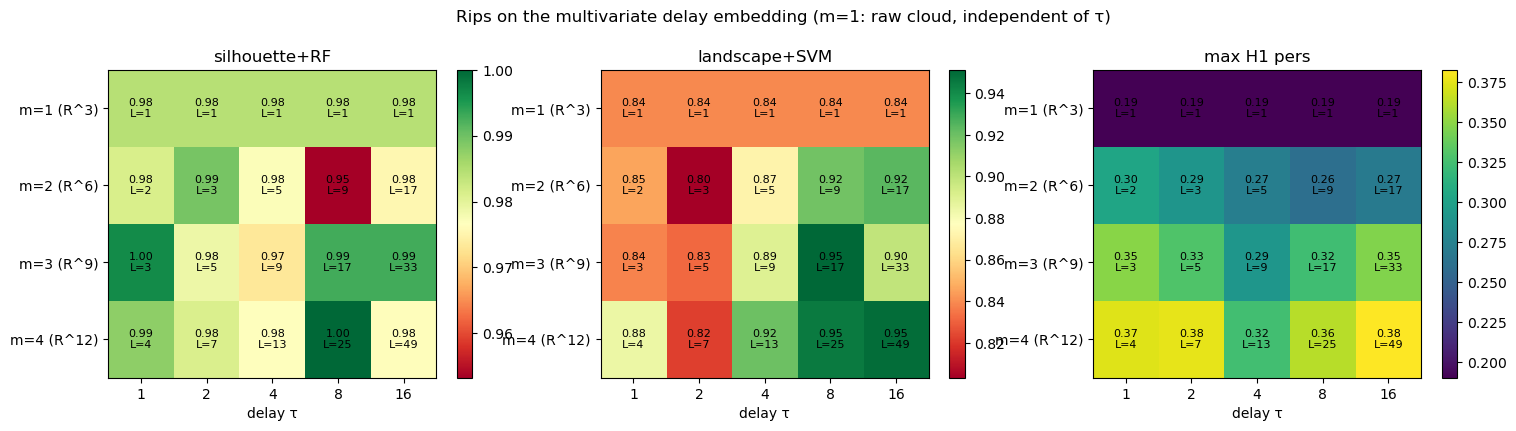

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col, cm in zip(axes, ["silhouette+RF", "landscape+SVM", "max H1 pers"], ["RdYlGn", "RdYlGn", "viridis"]):
    Z = np.full((len(M_LIST), len(TAU_LIST)), np.nan)
    for _, r in sweep.iterrows():
        for j, tau in enumerate(TAU_LIST if r.m > 1 else [1] * len(TAU_LIST)):
            Z[M_LIST.index(r.m), j] = r[col] if (r.m == 1 or tau == r.tau) else Z[M_LIST.index(r.m), j]
    im = ax.imshow(Z, cmap=cm, aspect="auto"); plt.colorbar(im, ax=ax)
    for i, m in enumerate(M_LIST):
        for j, tau in enumerate(TAU_LIST):
            L = (m - 1) * tau + 1
            ax.text(j, i, f"{Z[i, j]:.2f}\nL={L}", ha="center", va="center", fontsize=8)
    ax.set_xticks(range(len(TAU_LIST))); ax.set_xticklabels(TAU_LIST); ax.set_xlabel("delay τ")
    ax.set_yticks(range(len(M_LIST))); ax.set_yticklabels([f"m={m} (R^{3*m})" for m in M_LIST]); ax.set_title(col)
plt.suptitle("Rips on the multivariate delay embedding (m=1: raw cloud, independent of τ)", y=1.03); plt.show()

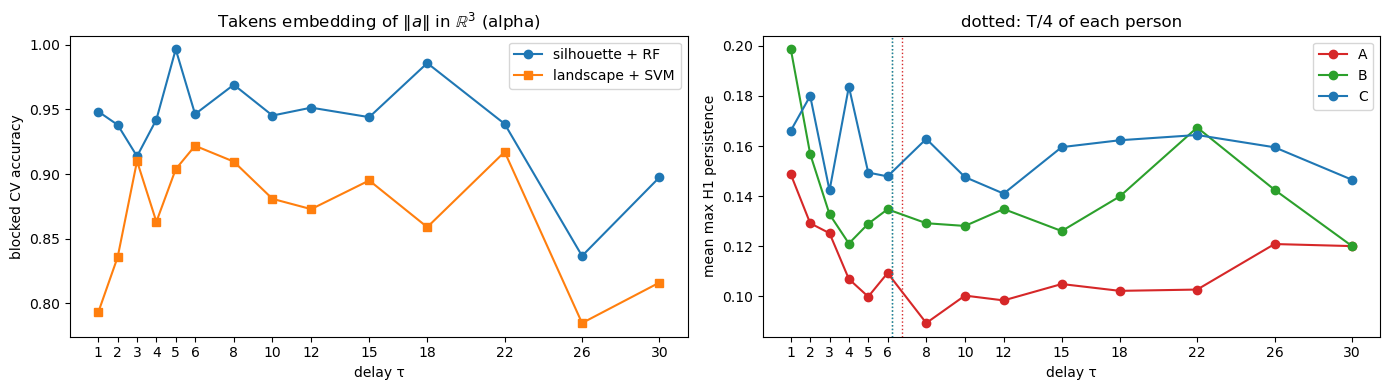

,tau,silhouette+RF,landscape+SVM,max H1 pers,max H1 pers A,max H1 pers B,max H1 pers C
0,1,0.948,0.793,0.171,0.149,0.199,0.166
1,2,0.938,0.836,0.155,0.129,0.157,0.180
2,3,0.914,0.910,0.133,0.125,0.133,0.142
3,4,0.942,0.863,0.137,0.107,0.121,0.184
4,5,0.996,0.904,0.126,0.100,0.129,0.149
5,6,0.946,0.922,0.131,0.109,0.135,0.148
6,8,0.969,0.910,0.127,0.089,0.129,0.163
7,10,0.945,0.881,0.125,0.100,0.128,0.148
8,12,0.951,0.873,0.125,0.098,0.135,0.141
9,15,0.944,0.895,0.130,0.105,0.126,0.160


In [26]:
TAU_NORM = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 18, 22, 26, 30]
cache = "cache_norm_sweep.pkl"
NSWEEP = pickle.load(open(cache, "rb")) if os.path.exists(cache) else {}
for tau in TAU_NORM:
    if tau not in NSWEEP: NSWEEP[tau] = tda_utils.parallel_norm_takens(X, 3, tau)
pickle.dump(NSWEEP, open(cache, "wb"))
nsweep = pd.DataFrame([dict(tau=tau, **quick_scores(NSWEEP[tau])) for tau in TAU_NORM])
for c in "ABC":
    nsweep[f"max H1 pers {c}"] = [np.mean([(d[1][:, 1] - d[1][:, 0]).max() for d, l in zip(NSWEEP[tau], y) if l == c]) for tau in TAU_NORM]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(nsweep.tau, nsweep["silhouette+RF"], "o-", label="silhouette + RF")
ax[0].plot(nsweep.tau, nsweep["landscape+SVM"], "s-", label="landscape + SVM")
ax[0].set_xlabel("delay τ"); ax[0].set_ylabel("blocked CV accuracy"); ax[0].legend()
for c in "ABC":
    ax[1].plot(nsweep.tau, nsweep[f"max H1 pers {c}"], "o-", c=COL[c], label=c)
    ax[1].axvline(T_med[c] / 4, c=COL[c], ls=":", lw=1)
ax[1].set_xlabel("delay τ"); ax[1].set_ylabel("mean max H1 persistence"); ax[1].legend(); ax[1].set_title("dotted: T/4 of each person")
for a in ax: a.set_xticks(TAU_NORM)
ax[0].set_title(r"Takens embedding of $\|a\|$ in $\mathbb{R}^3$ (alpha)")
plt.tight_layout(); plt.show()
nsweep.round(3)


**Analysis (5d).**
* **Gait period** (autocorrelation of $\|a\|$): $T\approx 27$ samples for A, 25 for B and C — this is the natural scale for the embedding window.
* **Multivariate delay embedding + Rips.** The robust pipeline (silhouette + RF) is insensitive to $(m,\tau)$: 0.95–1.00 everywhere.
  The fragile one (landscape + SVM) depends on the **window length** $L=(m-1)\tau+1$: 0.80–0.85 for $L\le 7$, ≥ 0.89 for $L\ge 9$, best 0.945–0.951 for $L=17$–$25$, i.e. **a window covering roughly 2/3 to one gait cycle**.
  The default of Question 4 ($m=3,\tau=2$, $L=5$) works but is not optimal; $\tau\approx 8$ ($L=17$) is a better choice. Longer embeddings ($m=4$) give larger $H_1$ loops.
* **Takens embedding of $\|a\|$.** The sinusoid intuition is **not** confirmed: the maximal $H_1$ persistence is largest at $\tau=1$ and roughly flat afterwards, without a maximum at $T/4$ — $\|a\|$ is a train of sharp impacts, not a sine wave, so its embedding is not one round loop.
  What *is* confirmed is the collapse at $\tau\approx T$: accuracy drops to 0.84 / 0.79 at $\tau=26$, because $(s(t),s(t+T),s(t+2T))$ lies near the diagonal. Best delays: $\tau=5$ (0.996) and $\tau=18$.
* At every delay the size of the dominant loop is ordered C > B > A, again reflecting the amplitude of the movement.


# 6. Final model and interpretation

**Chosen pipeline:** F4 sub/superlevel filtration of $\|a(t)\|$ → $H_0$ diagrams (valleys + peaks) → persistence silhouette → random forest.

blocked & purged CV accuracy of final model: 1.0


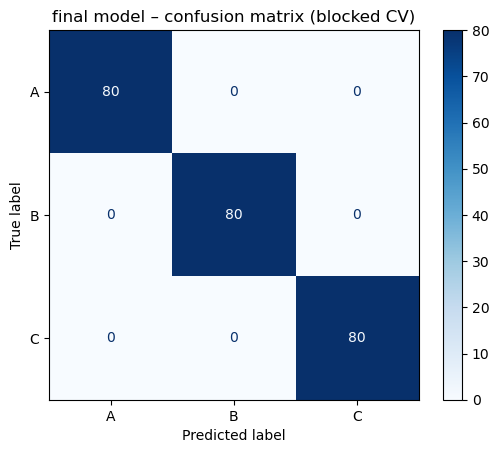

In [27]:
FINAL = ("F4 sublevel |a|", "silhouette", "RF")
D = train_diags[FINAL[0]]
pred_cv = np.empty(len(y), dtype=object)
for tr, te in blocked_purged_splits():
    m = build(*FINAL).fit([D[i] for i in tr], y[tr]); pred_cv[te] = m.predict([D[i] for i in te])
print("blocked & purged CV accuracy of final model:", (pred_cv == y).mean())
ConfusionMatrixDisplay(confusion_matrix(y, pred_cv.astype(str), labels=list("ABC")), display_labels=list("ABC")).plot(cmap="Blues")
plt.title("final model – confusion matrix (blocked CV)"); plt.show()

**Why does it work?** We fit the interpretable *statistics* version of the same filtration and look at the random-forest feature importances.

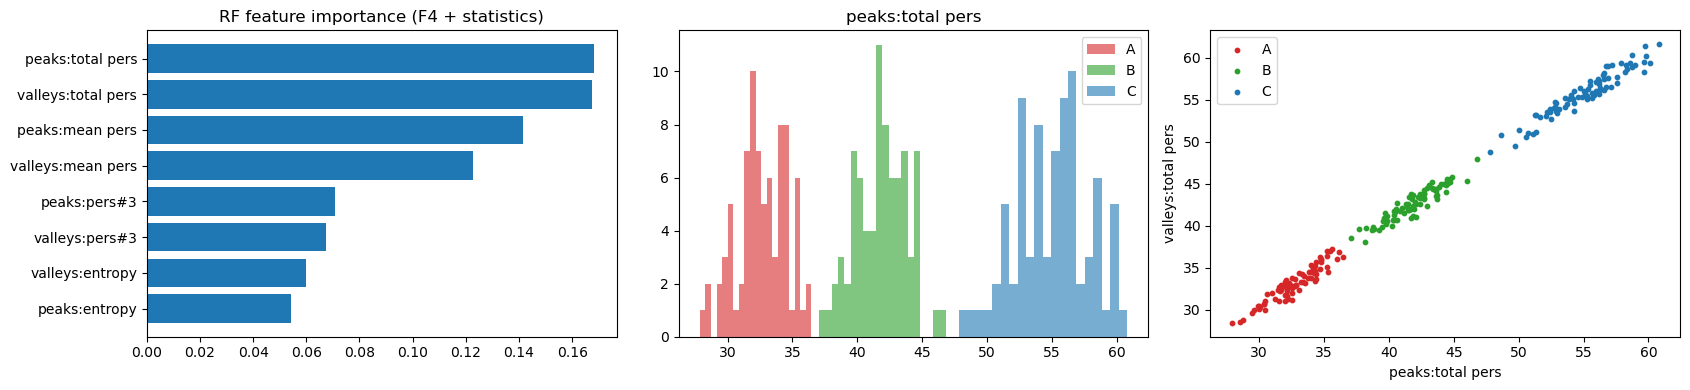

In [28]:
names = [f"{p}:{s}" for p in ["valleys", "peaks"] for s in ["#points", "total pers", "max pers", "mean pers", "entropy", "pers#1", "pers#2", "pers#3"]]
m_stats = build("F4 sublevel |a|", "stats", "RF").fit(D, y)
imp = m_stats[-1].feature_importances_; order = np.argsort(imp)[::-1][:8]
F = m_stats[0].transform(D)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].barh([names[i] for i in order][::-1], imp[order][::-1]); ax[0].set_title("RF feature importance (F4 + statistics)")
for c in "ABC":
    ax[1].hist(F[y == c, order[0]], bins=20, alpha=.6, color=COL[c], label=c)
    ax[2].scatter(F[y == c, order[0]], F[y == c, order[1]], s=10, c=COL[c], label=c)
ax[1].set_title(names[order[0]]); ax[1].legend()
ax[2].set_xlabel(names[order[0]]); ax[2].set_ylabel(names[order[1]]); ax[2].legend()
plt.tight_layout(); plt.show()

The dominant features are the **total and mean persistence** of the peaks and valleys of $\|a(t)\|$. A single number, the total persistence
of the peak diagram, already separates the three persons (histogram). For a function on a path graph one has the exact identity (checked numerically below)
$$\sum_{	ext{sub}}(d-b)+\sum_{	ext{super}}(d-b)+(\max s-\min s)=\sum_t|s(t+1)-s(t)| \quad(	ext{total variation}),$$
so this feature measures how strongly and how often the acceleration rises and falls during a window, while the individual
points of the diagram tell *how* this variation is distributed (a few big impacts vs many small oscillations). In gait terms: **impact intensity and cadence**, i.e. genuine properties of
the walker that do not depend on how the phone is oriented.

## Prediction of the evaluation set (Question 7)

In [29]:
s = np.linalg.norm(X[0], axis=1); dsub, dsup = train_diags["F4 sublevel |a|"][0]
print("total variation:", np.abs(np.diff(s)).sum())
print("pers(sub) + pers(super) + range:", (dsub[:,1]-dsub[:,0]).sum() + (dsup[:,1]-dsup[:,0]).sum() + s.max() - s.min())

total variation: 72.7656758683905
pers(sub) + pers(super) + range: 72.76567586839049


In [30]:
final_model = build(*FINAL).fit(train_diags[FINAL[0]], y)
eval_labels = list(final_model.predict(eval_diags[FINAL[0]]))

print("List of labels:", eval_labels)
for c in "ABC":
    print(f"Total number of class {c}: {eval_labels.count(c)}")

List of labels: ['B', 'C', 'B', 'B', 'A', 'A', 'B', 'C', 'B', 'B', 'B', 'B', 'A', 'B', 'B', 'A', 'B', 'A', 'B', 'A', 'A', 'B']
Total number of class A: 7
Total number of class B: 13
Total number of class C: 2


### Sanity checks

1. **Agreement between the best pipelines** (different filtrations / vectorizations): if the prediction is robust, independent pipelines agree.
2. **Phone-orientation baseline** (mean of the window, non-topological, *not* rotation invariant): an independent source of information.

In [31]:
best = results.sort_values("blocked_cv", ascending=False).head(8)
table = {}
for _, r in best.iterrows():
    key = (r.filtration, r.vectorization, r.classifier)
    table[" / ".join(key)] = build(*key).fit(train_diags[r.filtration], y).predict(eval_diags[r.filtration])
table["orientation baseline (mean vector)"] = RandomForestClassifier(500, random_state=0).fit(X.mean(1), y).predict(E.mean(1))
agree = pd.DataFrame(table).T
agree["agreement with final"] = [(np.array(v) == np.array(eval_labels)).mean() for v in table.values()]
agree["counts A/B/C"] = [tuple(list(v).count(c) for c in "ABC") for v in table.values()]
agree

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,agreement with final,counts A/B/C
F4 sublevel |a| / pimage / RF,B,C,B,B,A,A,B,C,B,B,...,B,A,B,A,B,A,A,B,1.000000,"(7, 13, 2)"
F4 sublevel |a| / silhouette / RF,B,C,B,B,A,A,B,C,B,B,...,B,A,B,A,B,A,A,B,1.000000,"(7, 13, 2)"
F4 sublevel |a| / stats / SVM,B,C,B,B,A,A,B,C,B,B,...,B,A,B,A,B,A,A,B,1.000000,"(7, 13, 2)"
F4 sublevel |a| / stats / RF,B,C,B,B,A,A,B,C,B,B,...,B,A,B,A,B,A,A,B,1.000000,"(7, 13, 2)"
F1 alpha(R^3) / stats / RF,B,C,B,B,A,A,B,C,B,B,...,B,A,B,A,B,A,A,B,0.954545,"(7, 12, 3)"
F4 sublevel |a| / landscape / SVM,B,C,B,B,A,A,B,C,B,B,...,B,A,B,A,B,A,A,B,0.954545,"(7, 12, 3)"
F3 alpha(Takens |a|) / silhouette / RF,B,C,B,B,A,A,B,C,B,B,...,B,A,B,A,B,A,A,B,0.954545,"(7, 12, 3)"
F4 sublevel |a| / landscape / RF,B,C,B,B,A,A,B,C,B,B,...,B,A,B,A,B,A,A,B,1.000000,"(7, 13, 2)"
orientation baseline (mean vector),B,C,B,B,A,A,B,C,B,B,...,B,A,B,A,B,A,A,B,1.000000,"(7, 13, 2)"


# 7. Synthesis for the presentation

The three routes, under **one common protocol** (blocked & purged 5-fold CV, random forest):

| route | representation | filtration |
|---|---|---|
| **A** (Method A of the subject) | raw cloud $\{a(t)\}\subset\mathbb{R}^3$ | Alpha |
| **B** (Method B of the subject) | delay vectors $(a(t),a(t+\ell),a(t+2\ell))\in\mathbb{R}^9$, $\ell=2$ (Question 4) and $\ell=8$ (best window of Section 5d) | Vietoris–Rips |
| **C** (our final model) | $\|a(t)\|$, using $\|Qa\|=\|a\|$ | sub/superlevel filtration on the path graph |

All three are rotation invariant: A and B depend only on pairwise distances (a rotation acts on $\mathbb{R}^9$ as the block-diagonal isometry $\mathrm{diag}(Q,Q,Q)$), C only on norms.
The figures and tables below are produced by `Final_Integration/p0_*.py` (re-run those scripts to regenerate them).

## 7.1 Which filtration and which homology dimension?

vectorization                landscape                                    \
homology                            H0 H0 peaks H0 valleys     H1   both   
route                                                                      
A: Alpha on R^3                  0.671      NaN        NaN  0.974  0.941   
B8: Rips on delay R^9, lag 8     0.937      NaN        NaN  0.927  0.993   
B: Rips on delay R^9             0.693      NaN        NaN  0.952  0.959   
C: sublevel |a(t)|                 NaN    0.996      0.993    NaN  0.996   

vectorization                silhouette                                    
homology                             H0 H0 peaks H0 valleys     H1   both  
route                                                                      
A: Alpha on R^3                   0.967      NaN        NaN  0.961  0.967  
B8: Rips on delay R^9, lag 8      0.969      NaN        NaN  0.982  1.000  
B: Rips on delay R^9              0.959      NaN        NaN  0.945  0.969  
C: sublevel |a(t)|                  NaN      1.0      0.986    NaN  1.000

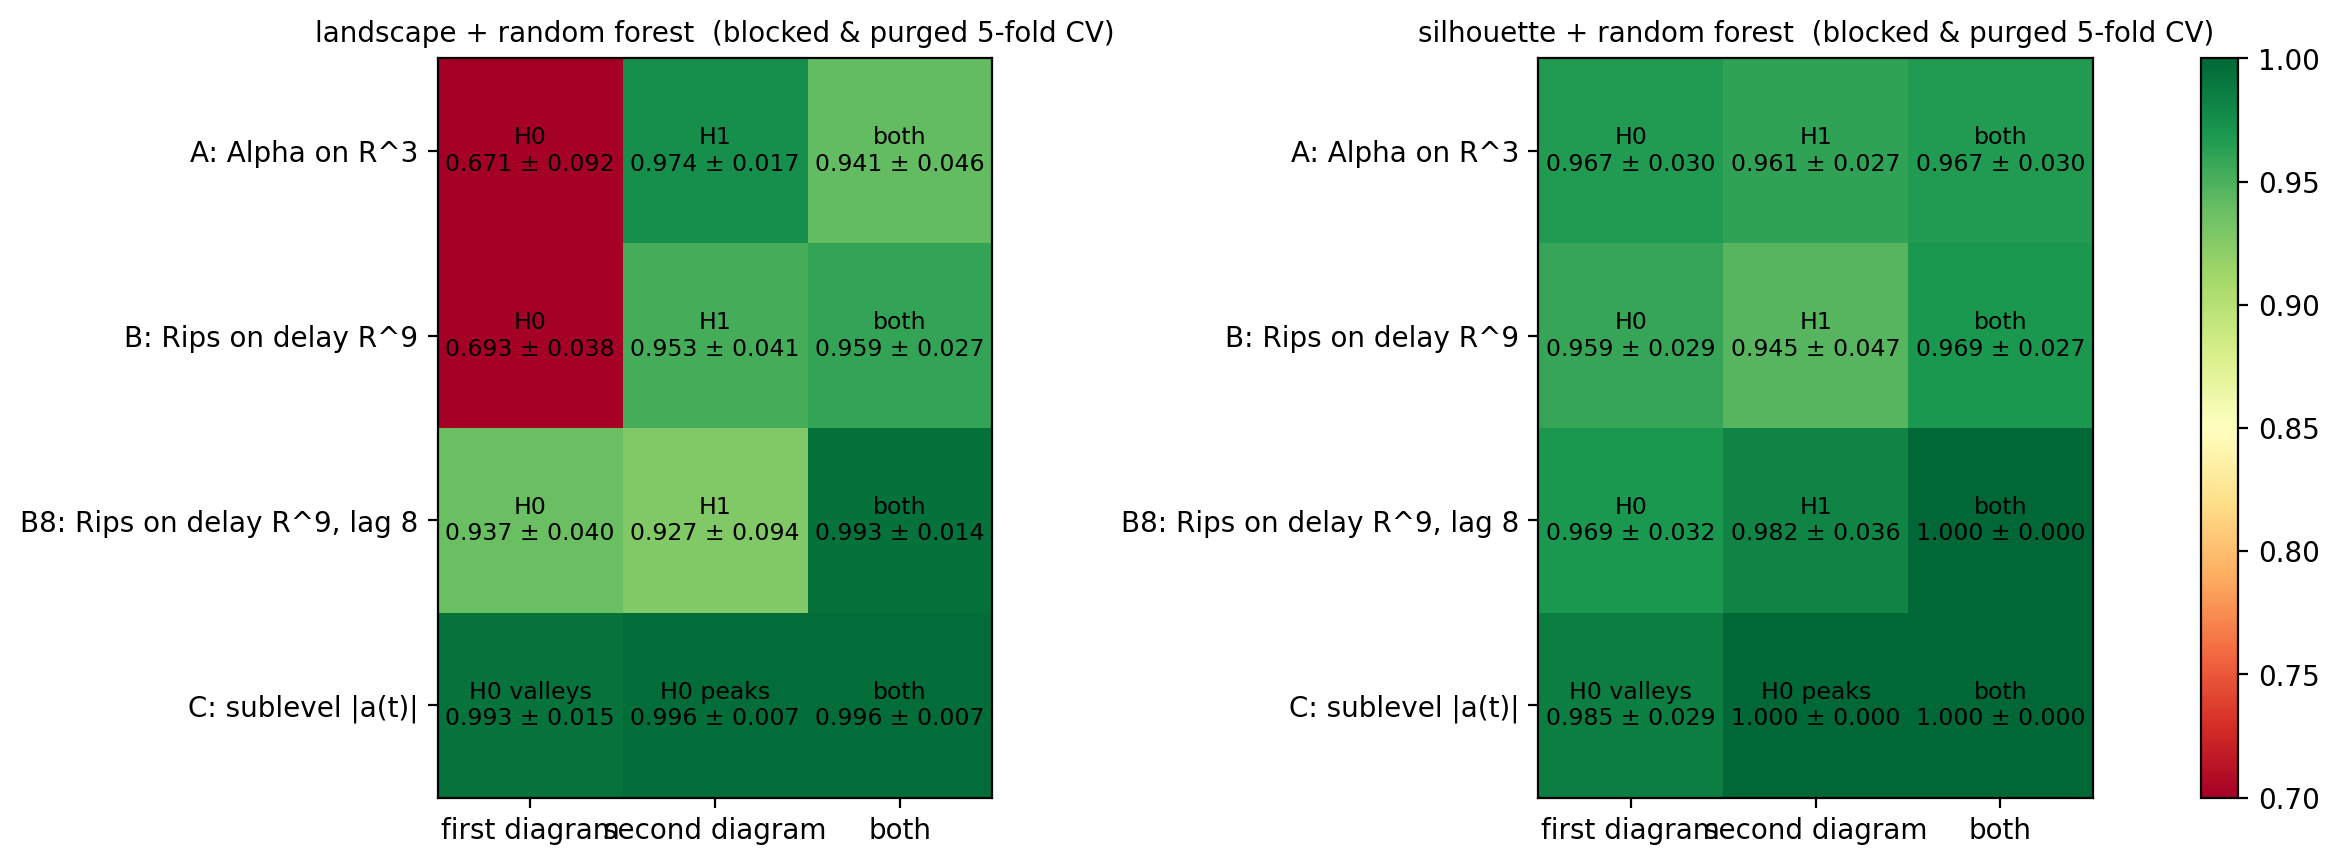

In [32]:
from IPython.display import Image, display
FI = "Final_Integration/"
t = pd.read_csv(FI + "tables/p0_1_route_x_homology.csv")
display(t.pivot_table(index="route", columns=["vectorization", "homology"], values="accuracy").round(3))
display(Image(FI + "figures/p0_1_route_x_homology.png", width=1000))

* **Route C is (with B, lag 8) the best and the simplest**: the peak diagram alone gives 1.000 (silhouette), the valleys alone 0.985–0.993.
* **Route B depends on the lag**: with the default $\ell=2$ (window of 5 samples) it is equivalent to the raw cloud A (≈ 0.95–0.97);
  with $\ell=8$ (window of 17 samples ≈ 2/3 of a gait cycle, as suggested by the lag sweep of Section 5d) it reaches **1.000** ($H_0+H_1$, silhouette)
  and $H_0$ + landscape jumps from 0.69 to 0.94 — the temporal information pays off once the window covers a substantial part of the step.
* **H0 vs H1** for A and B: with landscapes $H_0$ is poor (0.67–0.69) but with silhouettes it is as good as $H_1$ (0.96–0.97) — a property of the vectorization, not of $H_0$ (all births are 0, information is in the bulk of small features, which landscapes discard).
  Combining $H_0+H_1$ does not help much beyond the best single dimension.

## 7.2 Why topology? — rotate the phone
Every test window is rotated by its own random $Q\in SO(3)$; models are trained on the data as recorded.

,method,acc original test,acc rotated test,eval: predictions unchanged after rotation,eval counts A/B/C (original),eval counts A/B/C (rotated)
0,baseline: window mean (orientation),1.000,0.310,7/22,"(7, 13, 2)","(3, 12, 7)"
1,baseline: xyz mean/std/min/max,1.000,0.554,10/22,"(7, 13, 2)","(6, 11, 5)"
2,TDA route A: Alpha on R^3 (silhouette),0.967,0.967,22/22,"(7, 12, 3)","(7, 12, 3)"
3,TDA route B: Rips on delay R^9 (silhouette),0.969,0.969,22/22,"(7, 12, 3)","(7, 12, 3)"
4,TDA route C: sublevel |a(t)| (silhouette),1.000,1.000,22/22,"(7, 13, 2)","(7, 13, 2)"


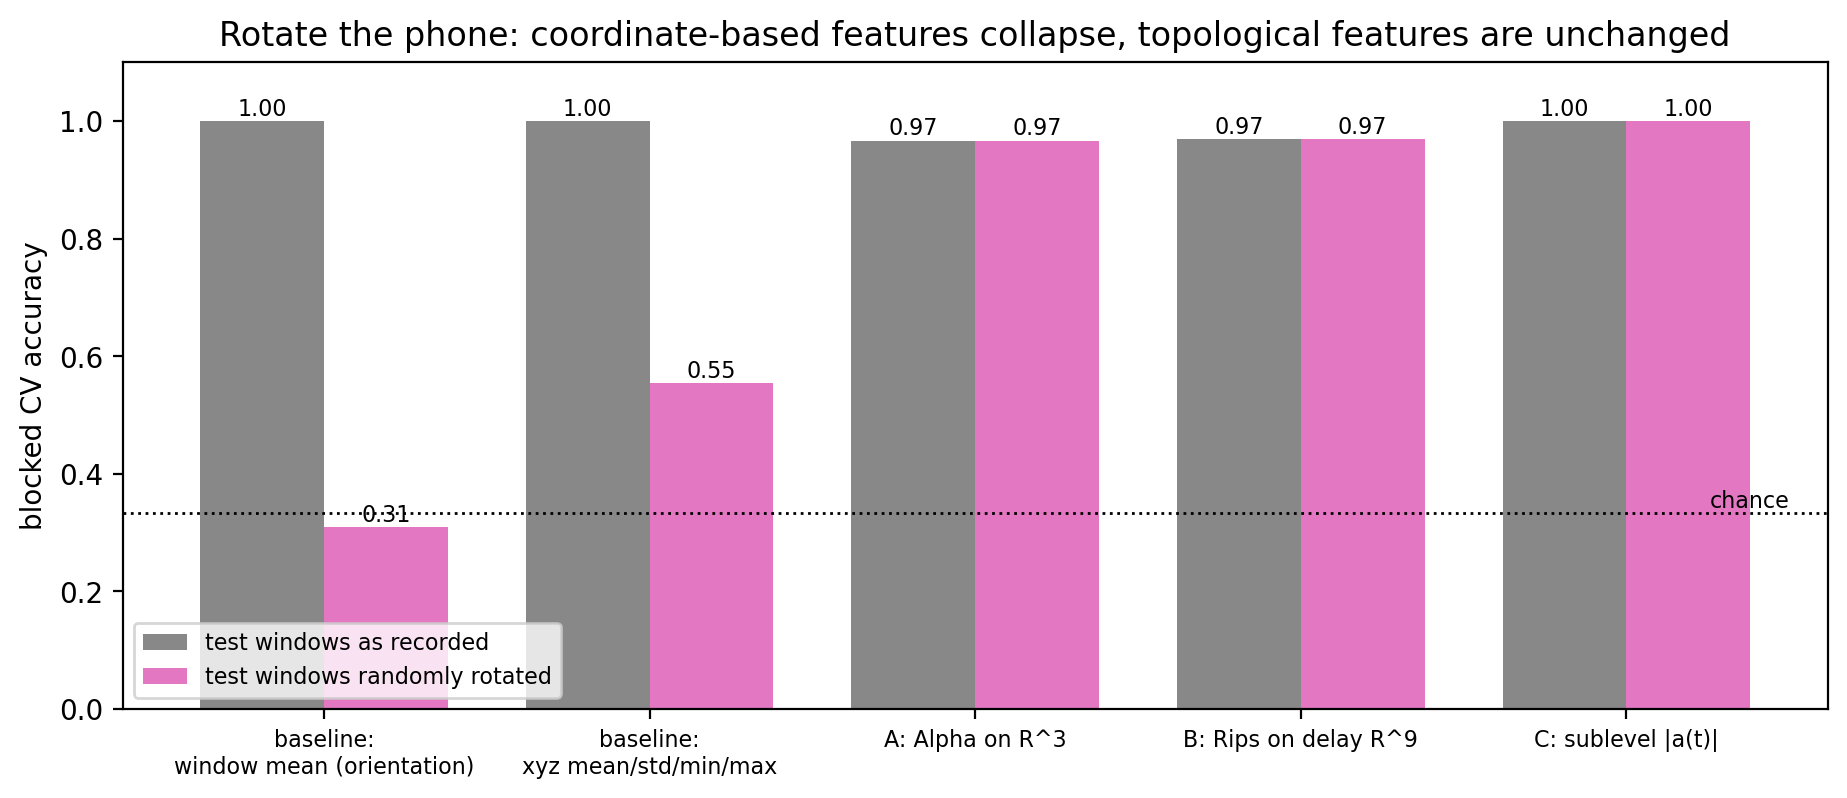

In [33]:
display(pd.read_csv(FI + "tables/p0_2_rotation_demo.csv"))
display(Image(FI + "figures/p0_2_rotation_demo.png", width=900))

Coordinate-based features (window mean, per-axis statistics) reach 100 % on the data as recorded, because each person's phone has its own orientation —
but they **collapse to chance (0.31) / 0.55** as soon as the orientation changes, and their predictions on the evaluation set change for 15 / 12 of the 22 windows.
The three topological routes give **identical** accuracies and predictions: they identify the *gait*, not the *phone position*.

## 7.3 Reading one feature

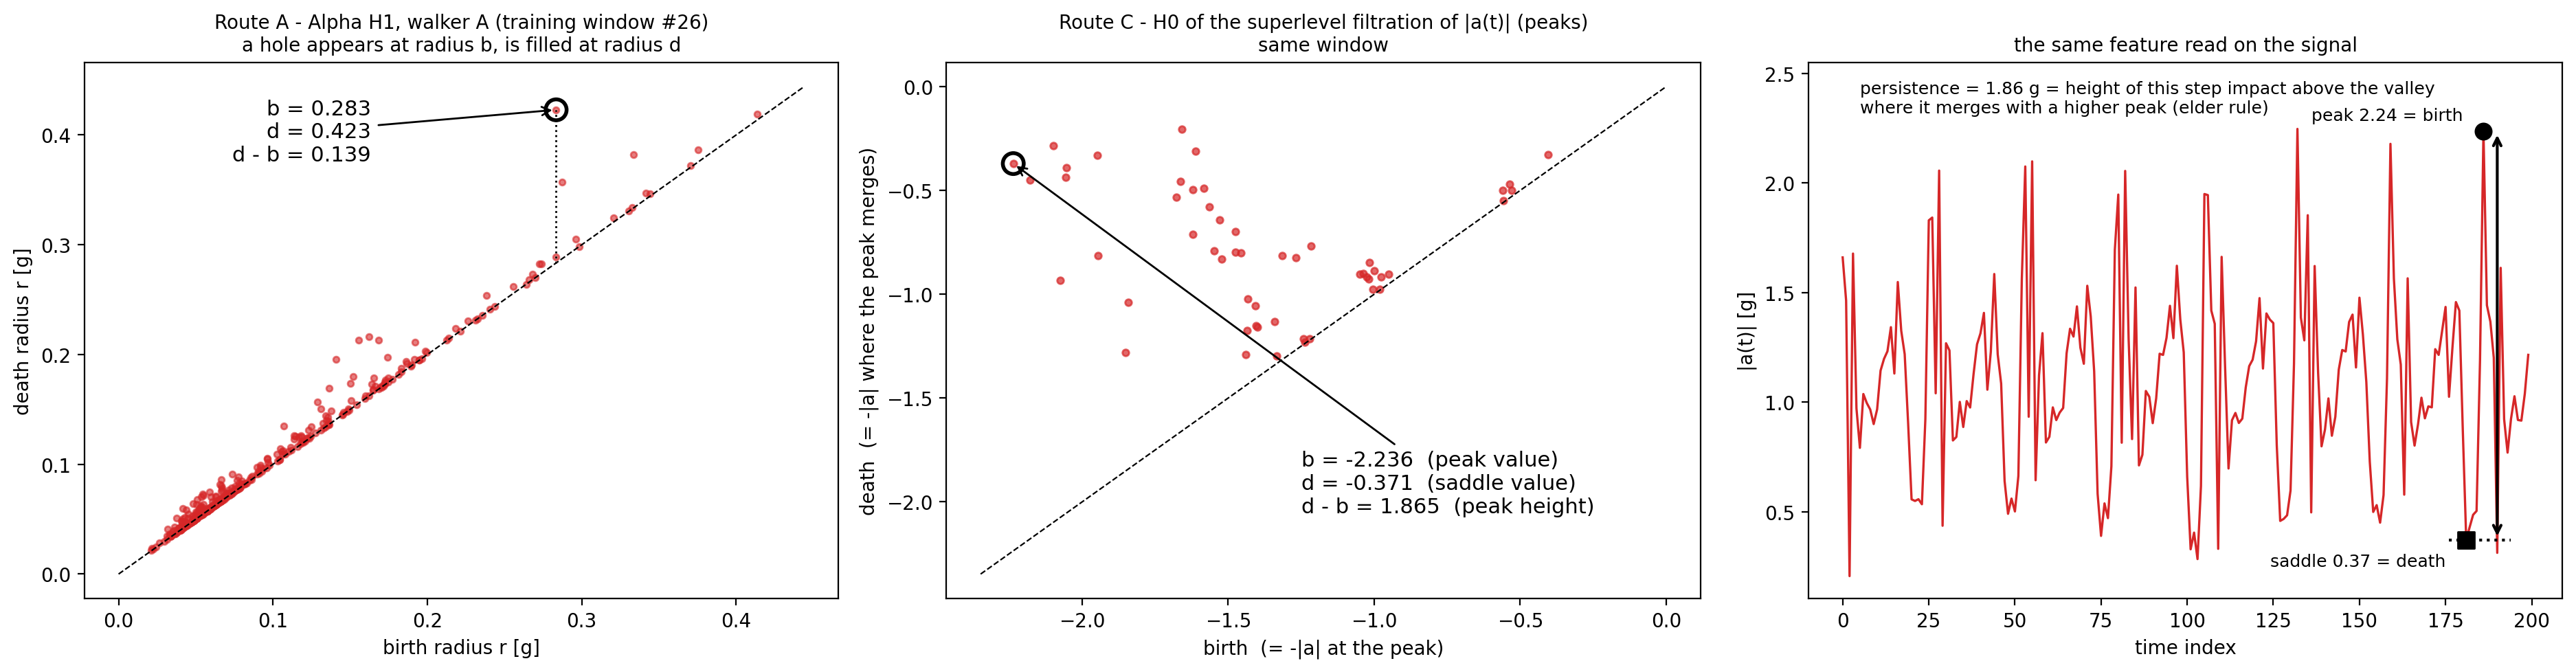

In [34]:
display(Image(FI + "figures/p1_4_annotated_diagrams.png", width=1100))

* Route A: an $H_1$ class of walker A born at radius $b=0.283$, filled at $d=0.423$: a hole of persistence $0.139$ g in the acceleration cloud.
* Route C: a peak of $\|a\|$ of height 2.236 g (birth $-2.236$ in the superlevel filtration) that merges with a higher peak through a valley at 0.371 g (death): persistence 1.865 g = height of this step impact above the valley.

## 7.4 Final answer: 22 labels in file order

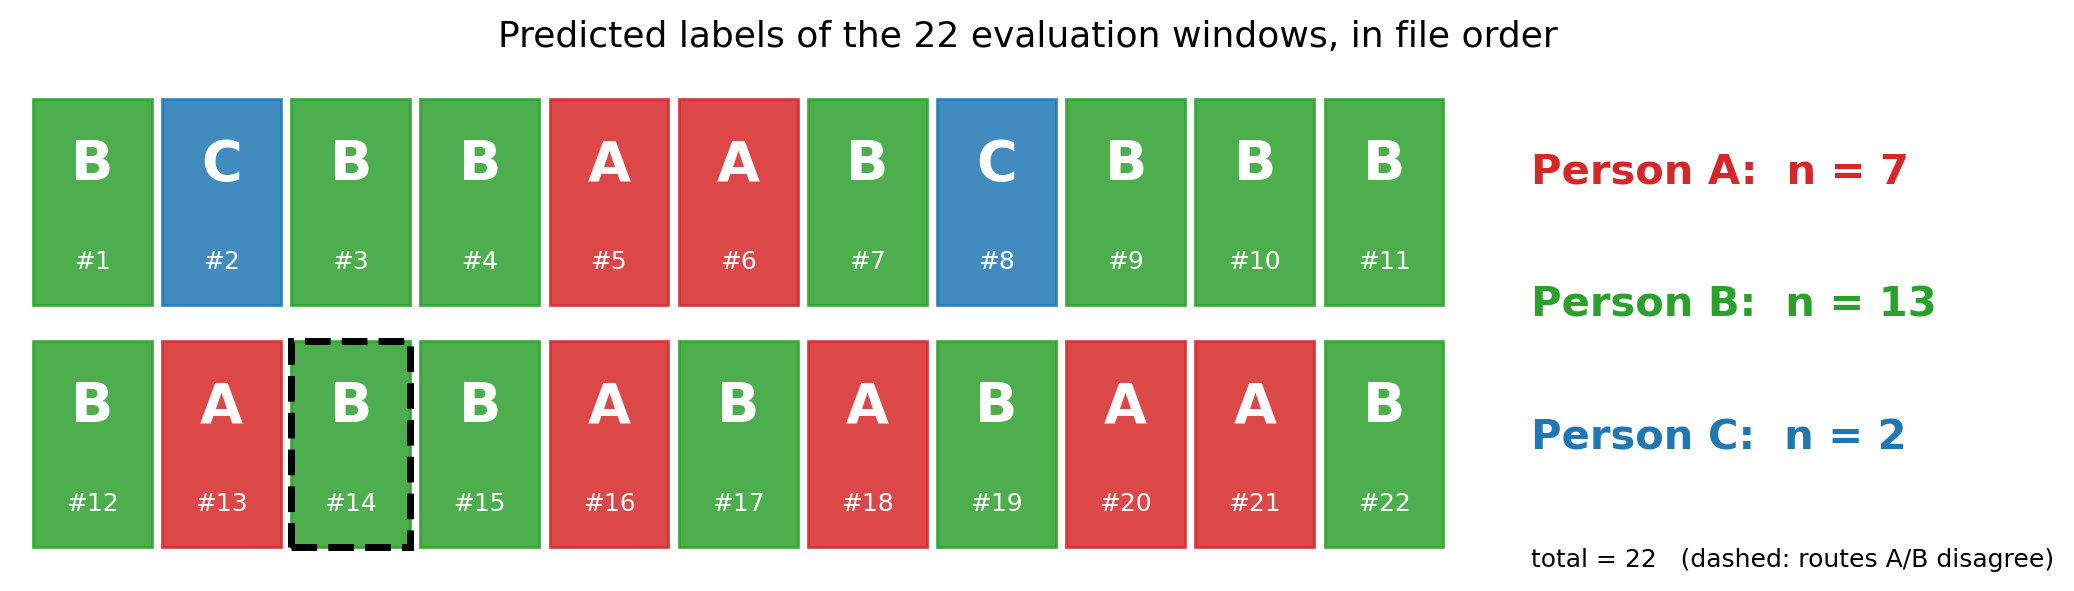

List of labels (windows 1..22): ['B', 'C', 'B', 'B', 'A', 'A', 'B', 'C', 'B', 'B', 'B', 'B', 'A', 'B', 'B', 'A', 'B', 'A', 'B', 'A', 'A', 'B']
Total number of class A: 7
Total number of class B: 13
Total number of class C: 2
sum = 22


,window,final label (route C),route A (Alpha),route B (delay Rips),all agree
13,14,B,C,C,False


In [35]:
pred = pd.read_csv(FI + "tables/final_predictions_22.csv")
assert list(pred["final label (route C)"]) == eval_labels          # same as Section 6
display(Image(FI + "figures/p0_3_final_predictions.png", width=1000))
print("List of labels (windows 1..22):", eval_labels)
for c in "ABC": print(f"Total number of class {c}: {eval_labels.count(c)}")
print("sum =", len(eval_labels))
display(pred[~pred["all agree"]])


Only window **#14** is predicted differently by routes A and B (C instead of B) — analysed in 7.6.
Geometric analysis of the Alpha diagrams (persistence diagrams, bottleneck matrices, MDS, rotation and subsampling robustness) is in `Track_A_Alpha_Analysis/report.md`.

## 7.5 How sure are we? Confidence and seed stability
Five pipelines (route C with silhouette / landscape, A, B with $\ell=2$ and $\ell=8$), each trained with 20 random-forest seeds; probability = fraction of trees voting for a class.


,window,final label,P(A) mean,P(B) mean,P(C) mean,margin (top1 - top2),seed agreement (final model)
0,1,B,0.000,1.000,0.000,1.000,1.0
1,2,C,0.000,0.000,1.000,1.000,1.0
2,3,B,0.000,1.000,0.000,1.000,1.0
3,4,B,0.000,1.000,0.000,1.000,1.0
4,5,A,1.000,0.000,0.000,1.000,1.0
5,6,A,0.998,0.000,0.002,0.996,1.0
6,7,B,0.000,1.000,0.000,1.000,1.0
7,8,C,0.000,0.000,1.000,0.999,1.0
8,9,B,0.000,1.000,0.000,1.000,1.0
9,10,B,0.000,1.000,0.000,1.000,1.0


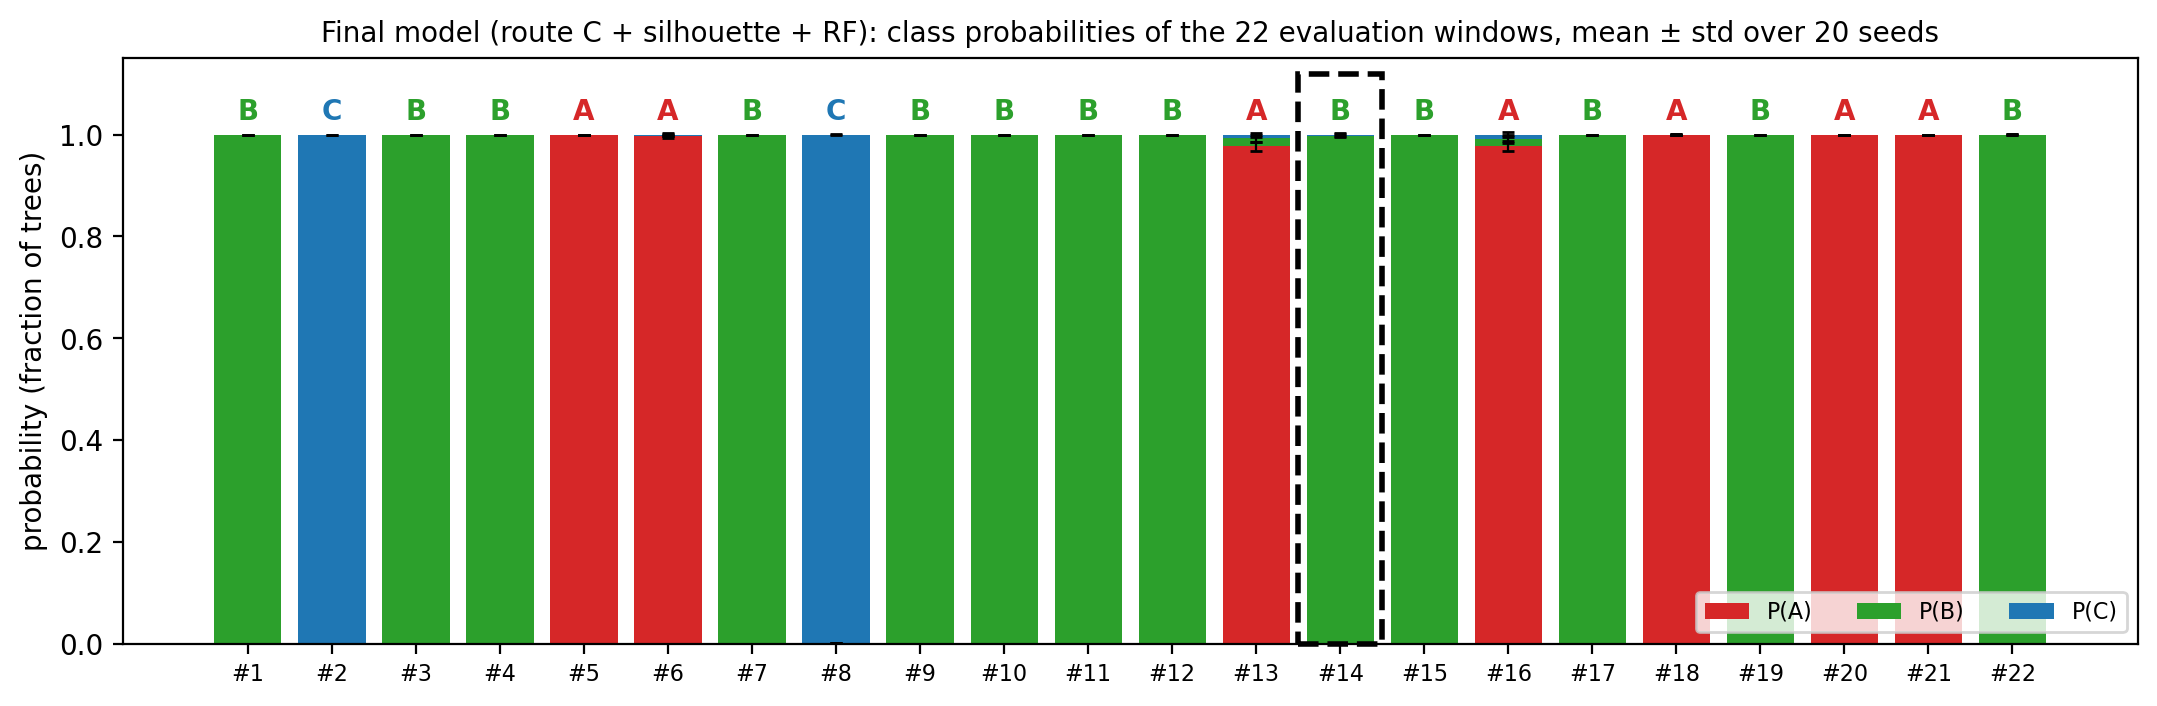

In [36]:
conf = pd.read_csv(FI + "tables/p0_4_confidence_22.csv")
display(conf[["window", "final label", "P(A) mean", "P(B) mean", "P(C) mean", "margin (top1 - top2)", "seed agreement (final model)"]].round(3))
display(Image(FI + "figures/p0_4_confidence_22.png", width=1000))

* Every one of the 22 predictions of the final model has probability ≥ 0.98 and a margin ≥ 0.96 between the two most likely classes.
* The labels are **identical for all 20 seeds** (seed agreement 100 % for every window, in every pipeline) → the counts **A = 7, B = 13, C = 2** are not a random-forest artefact.
* The pipelines agree on 21/22 windows. On **#14** both sides are *confident*: route C says B (0.998), routes A and B say C (0.97–0.998). Confidence alone cannot resolve it — we need to understand the window.

## 7.6 Window #14: the phone turns in the pocket

,P(A),P(B),P(C),label (majority over seeds),seed agreement
C + silhouette (final),0.000,0.998,0.002,B,1.0
C + landscape,0.000,1.000,0.000,B,1.0
A + silhouette,0.003,0.023,0.974,C,1.0
B lag 2 + silhouette,0.000,0.002,0.998,C,1.0
B lag 8 + silhouette,0.000,0.018,0.982,C,1.0


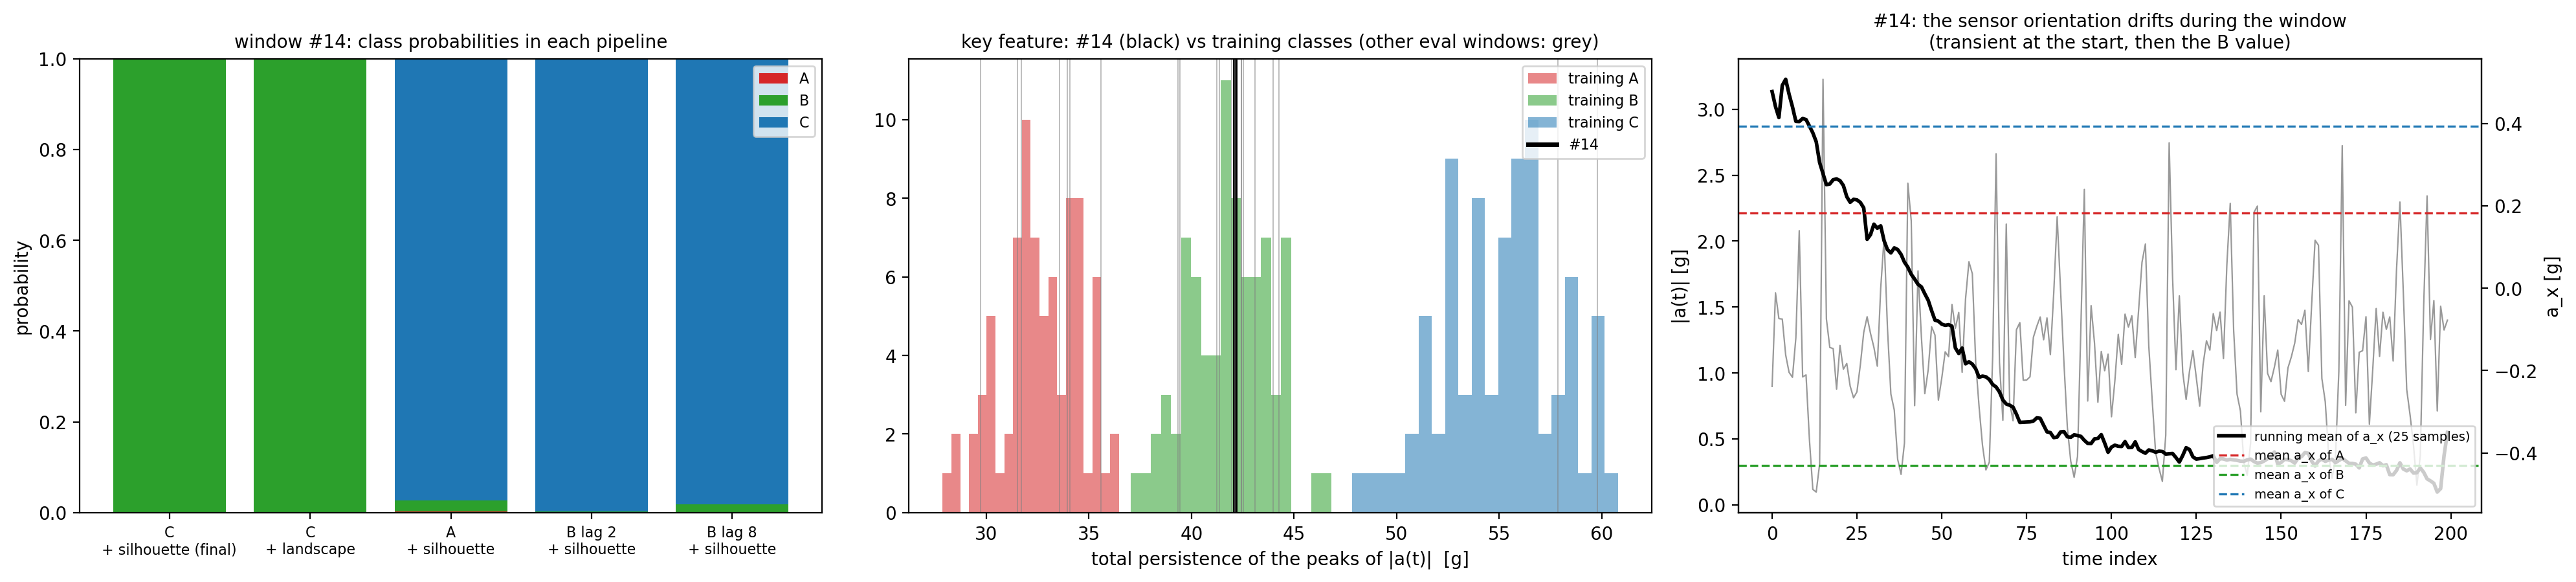

In [37]:
display(pd.read_csv(FI + "tables/p0_4_window14_all_pipelines.csv", index_col=0).round(3))
display(Image(FI + "figures/p0_4_window14.png", width=1100))

* On the key feature of route C (total persistence of the peaks of $\|a\|$), #14 = 42.1 g lies **inside the B range** of the training set (37.0–46.8) and far from C (≥ 47.8).
* The running mean of $a_x$ shows that the **gravity direction changes during the window**: the angle between the mean direction of its first 25 and last 100 samples is **47°**,
  while for training windows it is 1–4° (median) and ≤ 9° (95 %). The phone rotated in the pocket.
* Routes A and B are invariant to a **constant** rotation only (they use distances between samples taken at different times). A time-dependent rotation $Q(t)$ distorts the cloud;
  route C is invariant to **any** $Q(t)$ because $\|Q(t)a(t)\|=\|a(t)\|$. Controlled test: apply a rotation drifting from 0 to $\theta$ during each test window.

route,"A (Alpha, R^3)","B (delay Rips, lag 8)",C (|a(t)| sublevel)
drift angle (deg),,,
0,0.967,1.000,1.0
15,0.959,0.995,1.0
30,0.766,0.983,1.0
45,0.531,0.941,1.0
60,0.404,0.816,1.0
90,0.343,0.519,1.0


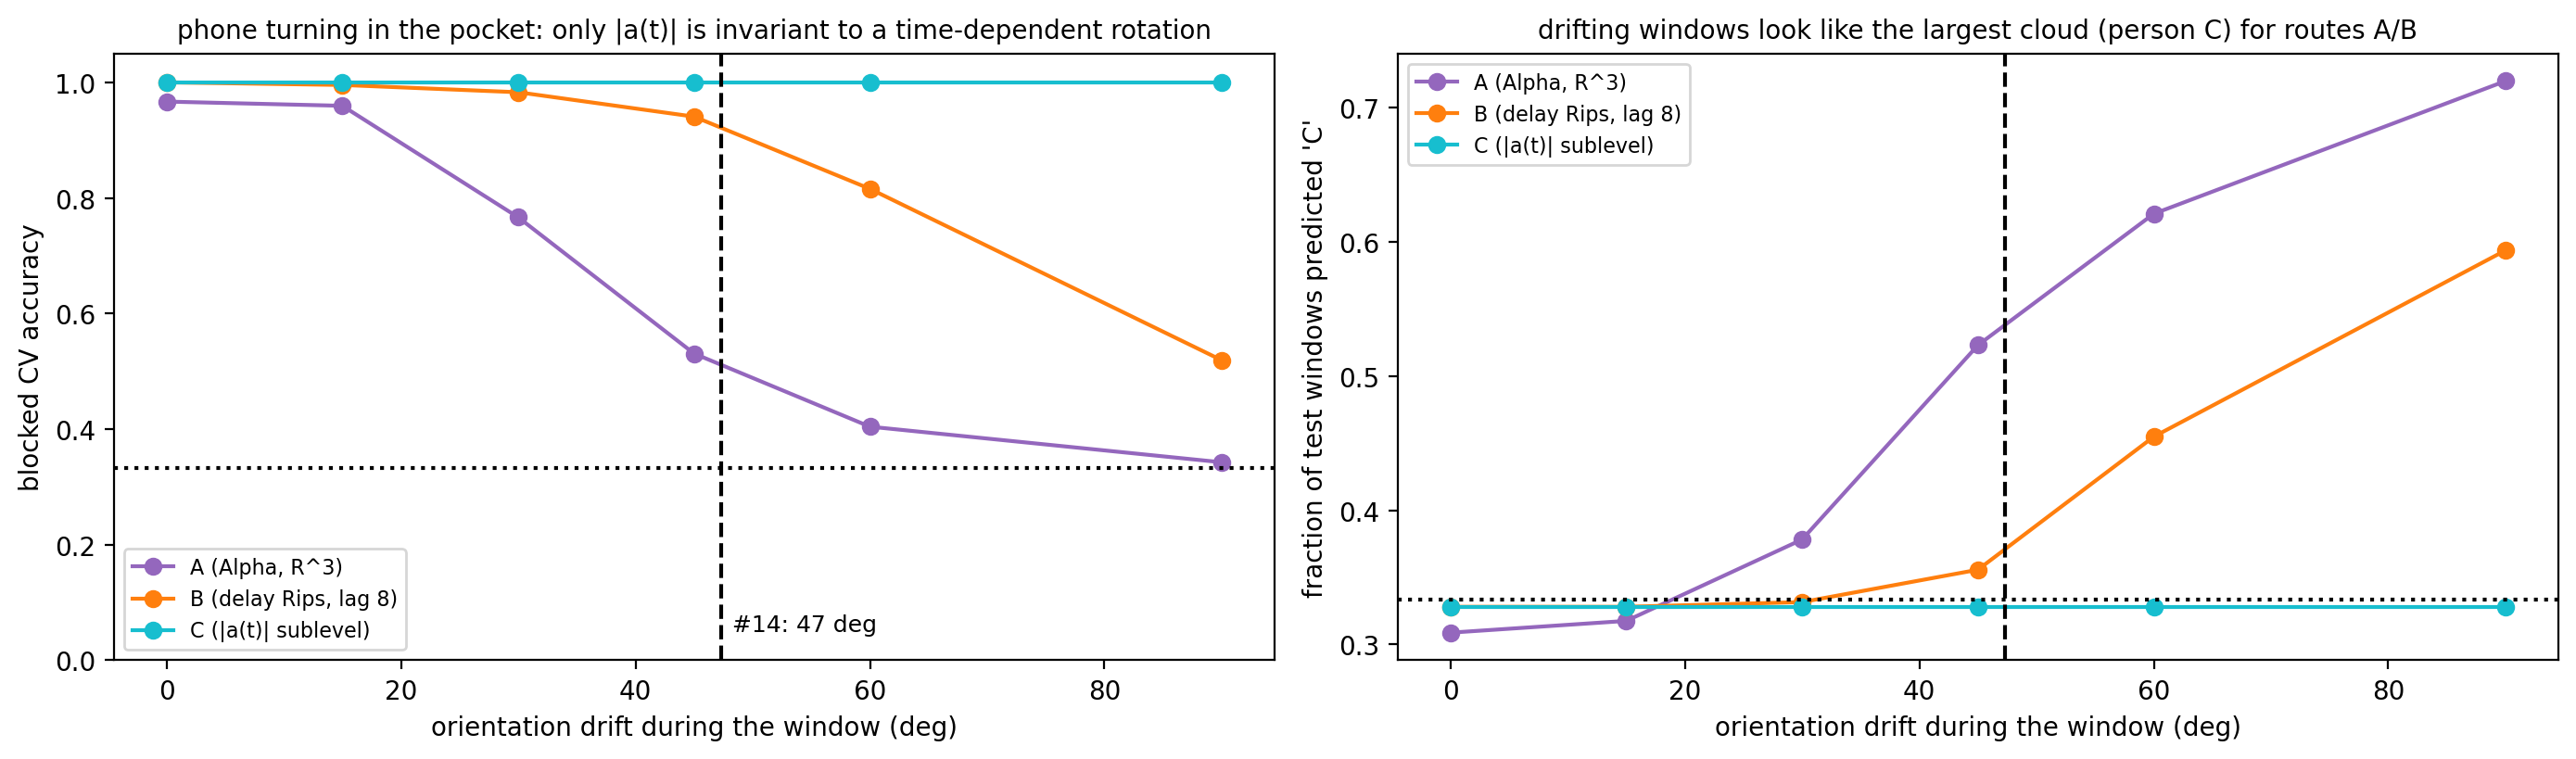

In [38]:
drift_tab = pd.read_csv(FI + "tables/p0_5_orientation_drift.csv")
display(drift_tab.pivot(index="drift angle (deg)", columns="route", values="accuracy").round(3))
display(Image(FI + "figures/p0_5_orientation_drift.png", width=1000))

* Route C stays at 100 % for every drift; route A drops to 0.53 at 45° and to chance at 90°; route B (lag 8) is more robust (0.94 at 45°) because a delay vector spans only 17 samples, during which the drift is small, but it also collapses (0.52 at 90°).
* Drifting windows are increasingly classified as **C** by routes A and B (the person with the largest acceleration cloud): exactly what happens to #14 (47° of drift).
* **Conclusion for #14:** we keep the route-C label **B**; the disagreement is explained by a known failure mode of the point-cloud routes, not by an ambiguity of the gait.
  This is also the strongest argument for the final choice of route C: it is invariant to the orientation of the phone **even when the orientation changes during the recording**.


# Conclusions

* **Data:** quasi-periodic gait signals (period ≈ 25–27 samples); the raw components depend on the unknown phone orientation, and the windows overlap in time → rotation-invariant constructions + blocked & purged cross-validation.
* **Filtrations:** Alpha on the raw cloud (A) reaches ≈ 0.96–0.97; Rips on the delay embedding (B) ≈ 0.97 with the default lag 2 and **1.00 with lag 8** (window ≈ 2/3 of a gait cycle); the sub/superlevel filtration of $\|a(t)\|$ (C) reaches 1.00 and is the cheapest and the easiest to interpret.
* **Homology:** for C the peak diagram alone suffices; for A/B $H_0$ and $H_1$ are comparable once a suitable vectorization (silhouette) is used.
* **Distances:** Wasserstein separates the persons better than bottleneck, because the information is spread over many small features.
* **Vectorization / classifier:** the choice of filtration matters most; landscapes discard the bulk of small features; random forests are the most robust classifier; the sliced-Wasserstein kernel works on every filtration.
* **Delay window:** a window covering ~2/3 of a gait cycle is best; a delay equal to the period collapses the embedding.
* **Why TDA:** coordinate features are perfect on the recorded data but fall to chance when the phone is rotated; topological features are unchanged.
* **Why route C:** it is invariant even to a rotation that changes *during* the window (phone turning in the pocket), where A and B fail (A: 0.53, B: 0.94 at 45° of drift; C: 1.00). This explains the only disagreement, window #14 (47° of drift).
* **Confidence:** all 22 predictions have probability ≥ 0.98 and are identical over 20 random seeds.
* **Interpretation:** the final model measures the strength and frequency of the step impacts (total persistence of peaks + valleys + range = total variation of $\|a\|$).
* **Result:** windows 1–22 → `B C B B A A B C B B B B A B B A B A B A A B`, i.e. **A = 7, B = 13, C = 2**.

*Limitations:* 3 walkers, one recording session each, overlapping windows; part of the signal is the amplitude of the movement (see Track A); a real system must be tested on new sessions.
